# __FINAL PROJECT PHASE II__

**Project:** Do SEC insider disclosures predict abnormal stock returns?

**Group members:** [Add names]

*Steps 1 to 7 are complete: cleaning and EDA are executed, and the data description, limitations, analysis plans, and reviewer questions are written. The research models remain unrun. Step 8 will complete the final readability review, fresh execution, and submission PDF.*

# __RESEARCH QUESTIONS__

An **abnormal return** is the difference between a stock's actual return and the return predicted by its historical relationship with the market. A **cumulative abnormal return (CAR)** adds these weekly differences over a specified horizon.

1. **Main question:** Do publicly disclosed insider open-market purchases at S&P 500 companies predict positive abnormal stock returns after the assumed public-information entry date?
2. **Horizon and direction:** How do the descriptive patterns and proposed purchase-versus-sale comparison vary over 1, 4, 13, and 26 weeks, with 13 weeks as the planned primary horizon?
3. **Role and size:** Among purchase events, are C-suite participation and larger dollar purchases associated with higher 13-week CARs, accounting for the number of insiders?
4. **Later-period extension:** Within 2023-2025 filings with observed plan flags, does the pattern differ for recorded pre-scheduled 10b5-1 plans? This extension is limited by the checkbox's introduction during 2023.

The event unit is one company, week, and direction. Entry is the first Friday close on or after filing date plus one business day, as implemented in Step 4. The EDA refines coverage and measurement; it does not establish causation or answer the planned role and size models.

### Importing

We use SciPy, NumPy, DuckDB, and Seaborn. Pandas reads and holds the data tables,
and Matplotlib supports the plots. These imports do not download any data.

In [1]:
# Imports and plot settings
import numpy as np
import pandas as pd
from scipy import stats
import duckdb
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### Data overview

We combine **SEC insider disclosures**, **historical S&P 500 membership**, and **Yahoo Finance adjusted daily prices** to study returns after public purchase and sale disclosures. The original filings cover **2020 Q1 through 2025 Q4**. Prices were collected separately on **October 19, 2026** and are already saved; the notebook reads them without making new downloads. SPY provides the market benchmark.

**Final company sample and retained observation counts:** Steps 1-2 retain **127,368 trades in 593 companies** (6,358 purchases and 121,010 sales). Step 4 aggregates these into **27,820 company-week-direction events**: 2,356 purchase events in 459 companies and 25,464 sale events in 582 companies. The two company counts overlap. Event dates run from January 3, 2020 to January 2, 2026; underlying filing dates run from January 2, 2020 to December 31, 2025. Historical membership, rather than today's index list, determines inclusion.

**Return coverage:** 540 of 593 companies have usable prices. CARs are available for 2,227 purchase and 23,873 sale events at each of the four horizons. Events lacking returns remain in the saved event table so exclusions can be audited.

**Shared raw-dataset link for reviewers:** [Project raw-data folder on the working branch](https://github.com/Vansh-Kakra/DSproject/tree/phase2-part1-sec-cleaning/insider-trading-phase2/data/raw). Large files may require downloading the repository rather than viewing them in GitHub's preview.

**Original sources:** [SEC quarterly insider datasets](https://www.sec.gov/data-research/sec-markets-data/insider-transactions-data-sets), [fja05680/sp500 membership history](https://github.com/fja05680/sp500), and [Yahoo Finance](https://finance.yahoo.com/) accessed with [yfinance](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html).

### Loading the SEC data

Our local SEC data covers **2020 Q1 through 2025 Q4**, in 24 quarter folders under
`data/raw/sec/`. For each quarter, we read `SUBMISSION`, `NONDERIV_TRANS`,
`REPORTINGOWNER`, and `FOOTNOTES` as tab-separated files using `pd.read_csv`.
We combine matching tables with `pd.concat` and add `SOURCE_QUARTER` so every row
can be traced back to its original quarter.

All fields are initially read as strings to preserve identifiers and inspect the
raw values before cleaning. Optional fields present in only some quarters are
retained, with missing values elsewhere. The raw TSV files are unchanged.

Run the cell below once after opening a fresh kernel. It prints progress as each
combined table finishes. The four table types total approximately **1.31 GB** on
disk before loading into memory. Stock-price files will be added separately.

In [2]:
# Load the four SEC tables from all 24 quarters, preserving their source quarter.
from pathlib import Path
from time import perf_counter

sec_dir = Path("data/raw/sec")
if not sec_dir.is_dir():
    sec_dir = Path("insider-trading-phase2/data/raw/sec")  # If opened from the repo root.

quarter_folders = [
    sec_dir / f"{year}q{quarter}_form345"
    for year in range(2020, 2026)
    for quarter in range(1, 5)
]
table_names = ["SUBMISSION", "NONDERIV_TRANS", "REPORTINGOWNER", "FOOTNOTES"]
missing_files = [str(folder / f"{table}.tsv")
                 for folder in quarter_folders for table in table_names
                 if not (folder / f"{table}.tsv").is_file()]
if missing_files:
    raise FileNotFoundError("Check the SEC folder location or missing files:\n" + "\n".join(missing_files))

sec_tables = {}
file_counts = []
load_start = perf_counter()
for table in table_names:
    quarter_frames = []
    for folder in quarter_folders:
        frame = pd.read_csv(folder / f"{table}.tsv", sep="\t", dtype="string")
        frame["SOURCE_QUARTER"] = folder.name.split("_")[0]
        file_counts.append({"quarter": frame["SOURCE_QUARTER"].iloc[0] if len(frame) else folder.name.split("_")[0],
                            "table": table, "rows": len(frame)})
        quarter_frames.append(frame)
    sec_tables[table] = pd.concat(quarter_frames, ignore_index=True)
    del quarter_frames, frame
    print(f"{table}: {len(sec_tables[table]):,} rows loaded", flush=True)

df_submission = sec_tables["SUBMISSION"]
df_transactions = sec_tables["NONDERIV_TRANS"]
df_owners = sec_tables["REPORTINGOWNER"]
df_footnotes = sec_tables["FOOTNOTES"]
df_file_counts = pd.DataFrame(file_counts)
print(f"Loaded {len(file_counts)} files from {len(quarter_folders)} quarters in {perf_counter() - load_start:.1f} seconds.")

SUBMISSION: 1,211,888 rows loaded


NONDERIV_TRANS: 1,841,674 rows loaded


REPORTINGOWNER: 1,323,957 rows loaded


FOOTNOTES: 2,865,764 rows loaded


Loaded 96 files from 24 quarters in 29.1 seconds.


### Initial inspection

The summary below reports the dimensions of each combined table and the row counts
for every quarter. Use these checks to look for empty or incomplete inputs before
cleaning. `df_transactions.head()` displays a few raw transaction rows; these
counts include all nonderivative transaction codes and have not been filtered to P/S.

In [3]:
# Inspect combined table sizes, source-quarter coverage, and raw transaction fields.
from IPython.display import display

summary = pd.DataFrame([
    {"table": name, "rows": len(frame), "columns": frame.shape[1],
     "quarters": frame["SOURCE_QUARTER"].nunique()}
    for name, frame in sec_tables.items()
])
display(summary)
display(df_file_counts.pivot(index="quarter", columns="table", values="rows"))
print("Transaction columns:", df_transactions.columns.tolist())
display(df_transactions.head())

,table,rows,columns,quarters
0,SUBMISSION,1211888,15,24
1,NONDERIV_TRANS,1841674,29,24
2,REPORTINGOWNER,1323957,14,24
3,FOOTNOTES,2865764,4,24


table,FOOTNOTES,NONDERIV_TRANS,REPORTINGOWNER,SUBMISSION
quarter,,,,
2020q1,159716,105852,73693,69408
2020q2,113675,70429,55817,51459
2020q3,92931,60619,43766,39096
2020q4,108077,72973,49045,43607
2021q1,188895,125620,81046,74944
2021q2,140976,89108,66036,58798
2021q3,111270,74002,50774,44057
2021q4,118799,80096,52858,46675
2022q1,171741,110327,76260,71395


Transaction columns: ['ACCESSION_NUMBER', 'NONDERIV_TRANS_SK', 'SECURITY_TITLE', 'SECURITY_TITLE_FN', 'TRANS_DATE', 'TRANS_DATE_FN', 'DEEMED_EXECUTION_DATE', 'DEEMED_EXECUTION_DATE_FN', 'TRANS_FORM_TYPE', 'TRANS_CODE', 'EQUITY_SWAP_INVOLVED', 'EQUITY_SWAP_TRANS_CD_FN', 'TRANS_TIMELINESS', 'TRANS_TIMELINESS_FN', 'TRANS_SHARES', 'TRANS_SHARES_FN', 'TRANS_PRICEPERSHARE', 'TRANS_PRICEPERSHARE_FN', 'TRANS_ACQUIRED_DISP_CD', 'TRANS_ACQUIRED_DISP_CD_FN', 'SHRS_OWND_FOLWNG_TRANS', 'SHRS_OWND_FOLWNG_TRANS_FN', 'VALU_OWND_FOLWNG_TRANS', 'VALU_OWND_FOLWNG_TRANS_FN', 'DIRECT_INDIRECT_OWNERSHIP', 'DIRECT_INDIRECT_OWNERSHIP_FN', 'NATURE_OF_OWNERSHIP', 'NATURE_OF_OWNERSHIP_FN', 'SOURCE_QUARTER']


,ACCESSION_NUMBER,NONDERIV_TRANS_SK,SECURITY_TITLE,SECURITY_TITLE_FN,TRANS_DATE,TRANS_DATE_FN,DEEMED_EXECUTION_DATE,DEEMED_EXECUTION_DATE_FN,TRANS_FORM_TYPE,TRANS_CODE,...,TRANS_ACQUIRED_DISP_CD_FN,SHRS_OWND_FOLWNG_TRANS,SHRS_OWND_FOLWNG_TRANS_FN,VALU_OWND_FOLWNG_TRANS,VALU_OWND_FOLWNG_TRANS_FN,DIRECT_INDIRECT_OWNERSHIP,DIRECT_INDIRECT_OWNERSHIP_FN,NATURE_OF_OWNERSHIP,NATURE_OF_OWNERSHIP_FN,SOURCE_QUARTER
0,0001446472-20-000002,281943,Common Stock,<NA>,31-MAR-2020,<NA>,<NA>,<NA>,4,P,...,<NA>,1537800.0,F2,<NA>,<NA>,D,<NA>,<NA>,<NA>,2020q1
1,0001084991-20-000014,379212,Common Stock,<NA>,31-MAR-2020,<NA>,<NA>,<NA>,4,M,...,<NA>,8560.0,<NA>,<NA>,<NA>,I,<NA>,By Rabbi Trust,<NA>,2020q1
2,0001104659-20-041411,245379,Common Stock,<NA>,28-MAR-2020,<NA>,<NA>,<NA>,4,F,...,<NA>,54890.0,<NA>,<NA>,<NA>,D,<NA>,<NA>,<NA>,2020q1
3,0001104659-20-041411,245380,Common Stock,<NA>,31-MAR-2020,<NA>,<NA>,<NA>,4,F,...,<NA>,54338.0,<NA>,<NA>,<NA>,D,<NA>,<NA>,<NA>,2020q1
4,0001104659-20-041409,272457,Common Stock,<NA>,28-MAR-2020,<NA>,<NA>,<NA>,4,F,...,<NA>,24497.0,<NA>,<NA>,<NA>,D,<NA>,<NA>,<NA>,2020q1


### Preview the extracted SEC tables

Show the first five rows of each extracted SEC DataFrame.


In [4]:
display(df_submission.head())
display(df_transactions.head())
display(df_owners.head())
display(df_footnotes.head())


,ACCESSION_NUMBER,FILING_DATE,PERIOD_OF_REPORT,DATE_OF_ORIG_SUB,NO_SECURITIES_OWNED,NOT_SUBJECT_SEC16,FORM3_HOLDINGS_REPORTED,FORM4_TRANS_REPORTED,DOCUMENT_TYPE,ISSUERCIK,ISSUERNAME,ISSUERTRADINGSYMBOL,REMARKS,SOURCE_QUARTER,AFF10B5ONE
0,0001047340-20-000142,31-MAR-2020,27-MAR-2020,<NA>,<NA>,0,<NA>,<NA>,4,0001047340,FRESH DEL MONTE PRODUCE INC,FDP,<NA>,2020q1,<NA>
1,0001209191-20-021789,31-MAR-2020,27-MAR-2020,<NA>,<NA>,0,<NA>,<NA>,4,0001400810,"HCI Group, Inc.",HCI,<NA>,2020q1,<NA>
2,0001593034-20-000030,31-MAR-2020,29-MAR-2020,<NA>,<NA>,0,<NA>,<NA>,4,0001593034,Endo International plc,ENDP,<NA>,2020q1,<NA>
3,0001726978-20-000119,31-MAR-2020,27-MAR-2020,<NA>,<NA>,0,<NA>,<NA>,4,0001726978,"Goosehead Insurance, Inc.",GSHD,The sales reported were effected pursuant to a...,2020q1,<NA>
4,0001289419-20-000061,31-MAR-2020,27-MAR-2020,<NA>,<NA>,<NA>,<NA>,<NA>,4,0001289419,"Morningstar, Inc.",MORN,<NA>,2020q1,<NA>


,ACCESSION_NUMBER,NONDERIV_TRANS_SK,SECURITY_TITLE,SECURITY_TITLE_FN,TRANS_DATE,TRANS_DATE_FN,DEEMED_EXECUTION_DATE,DEEMED_EXECUTION_DATE_FN,TRANS_FORM_TYPE,TRANS_CODE,...,TRANS_ACQUIRED_DISP_CD_FN,SHRS_OWND_FOLWNG_TRANS,SHRS_OWND_FOLWNG_TRANS_FN,VALU_OWND_FOLWNG_TRANS,VALU_OWND_FOLWNG_TRANS_FN,DIRECT_INDIRECT_OWNERSHIP,DIRECT_INDIRECT_OWNERSHIP_FN,NATURE_OF_OWNERSHIP,NATURE_OF_OWNERSHIP_FN,SOURCE_QUARTER
0,0001446472-20-000002,281943,Common Stock,<NA>,31-MAR-2020,<NA>,<NA>,<NA>,4,P,...,<NA>,1537800.0,F2,<NA>,<NA>,D,<NA>,<NA>,<NA>,2020q1
1,0001084991-20-000014,379212,Common Stock,<NA>,31-MAR-2020,<NA>,<NA>,<NA>,4,M,...,<NA>,8560.0,<NA>,<NA>,<NA>,I,<NA>,By Rabbi Trust,<NA>,2020q1
2,0001104659-20-041411,245379,Common Stock,<NA>,28-MAR-2020,<NA>,<NA>,<NA>,4,F,...,<NA>,54890.0,<NA>,<NA>,<NA>,D,<NA>,<NA>,<NA>,2020q1
3,0001104659-20-041411,245380,Common Stock,<NA>,31-MAR-2020,<NA>,<NA>,<NA>,4,F,...,<NA>,54338.0,<NA>,<NA>,<NA>,D,<NA>,<NA>,<NA>,2020q1
4,0001104659-20-041409,272457,Common Stock,<NA>,28-MAR-2020,<NA>,<NA>,<NA>,4,F,...,<NA>,24497.0,<NA>,<NA>,<NA>,D,<NA>,<NA>,<NA>,2020q1


,ACCESSION_NUMBER,RPTOWNERCIK,RPTOWNERNAME,RPTOWNER_RELATIONSHIP,RPTOWNER_TITLE,RPTOWNER_TXT,RPTOWNER_STREET1,RPTOWNER_STREET2,RPTOWNER_CITY,RPTOWNER_STATE,RPTOWNER_ZIPCODE,RPTOWNER_STATE_DESC,FILE_NUMBER,SOURCE_QUARTER
0,0001446472-20-000002,0001441252,Pratt Brian,TenPercentOwner,<NA>,<NA>,"5950 BERKSHIRE LANE, STE. 800",<NA>,DALLAS,TX,75225,<NA>,001-36541,2020q1
1,0001084991-20-000014,0001271773,HUGHES WILLIAM F JR,Director,<NA>,<NA>,42921 NORMANDY LANE,<NA>,LANCASTER,CA,93536,<NA>,001-31398,2020q1
2,0001104659-20-041411,0001579464,Schrepfer Robert W,Officer,SVP - New Bus Dev & Spec Sales,<NA>,"C/O ANI PHARMACEUTICALS, INC.",210 MAIN STREET WEST,BAUDETTE,MN,56623,<NA>,001-31812,2020q1
3,0001104659-20-041409,0001674236,CAREY STEPHEN P.,Officer,Vice President and CFO,<NA>,"C/O ANI PHARMACEUTICALS, INC",210 MAIN STREET WEST,BAUDETTE,MN,56623,<NA>,001-31812,2020q1
4,0001209191-20-021971,0001055565,STULL STEVEN T,Director,<NA>,<NA>,3280 PEACHTREE RD.,SUITE 2400,ATLANTA,GA,30305,<NA>,001-35004,2020q1


,ACCESSION_NUMBER,FOOTNOTE_ID,FOOTNOTE_TXT,SOURCE_QUARTER
0,0001446472-20-000002,F1,The price reported in Column 4 is a weighted a...,2020q1
1,0001446472-20-000002,F2,These shares are held as community property by...,2020q1
2,0001084991-20-000014,F2,Not Applicable. Each RSU represents the right ...,2020q1
3,0001084991-20-000014,F1,The shares were issued in connection with the ...,2020q1
4,0001104659-20-041411,F2,Shares withheld for tax purposes exempt under ...,2020q1


### Loading historical S&P 500 membership

The CSV in `data/raw/historical/` contains a `date` and a comma-separated list of
`tickers` for each membership snapshot. Read it with `pd.read_csv`; Pandas preserves
that quoted ticker list as one column.

These are dated snapshots, not a row for every trading day. When matching filings
later, use the most recent snapshot on or before the disclosure date, and handle
historical ticker changes explicitly. We are only loading and inspecting the file here.

Source: [fja05680/sp500 historical membership](https://github.com/fja05680/sp500).

In [5]:
# Load and inspect the supplied historical membership CSV.
from pathlib import Path

raw_dir = Path("data/raw")
if not raw_dir.is_dir():
    raw_dir = Path("insider-trading-phase2/data/raw")

historical_file = raw_dir / "historical" / "S&P 500 Historical Components & Changes (Updated).csv"
df_historical = pd.read_csv(historical_file)
historical_dates = pd.to_datetime(df_historical["date"], format="%Y-%m-%d")
print(f"Historical membership: {len(df_historical):,} rows, {df_historical.shape[1]} columns")
print(f"Snapshot dates: {historical_dates.min().date()} to {historical_dates.max().date()}")
print("Missing values:", df_historical.isna().sum().to_dict())
display(df_historical.head())

Historical membership: 2,720 rows, 2 columns
Snapshot dates: 1996-01-02 to 2026-08-18
Missing values: {'date': 0, 'tickers': 0}


,date,tickers
0,1996-01-02,"AAL,AAMRQ,AAPL,ABI,ABS,ABT,ABX,ACKH,ACV,ADM,AD..."
1,1996-01-03,"AAL,AAMRQ,AAPL,ABI,ABS,ABT,ABX,ACKH,ACV,ADM,AD..."
2,1996-01-04,"AAL,AAMRQ,AAPL,ABI,ABS,ABT,ABX,ACKH,ACV,ADM,AD..."
3,1996-01-10,"AAL,AAMRQ,AAPL,ABI,ABS,ABT,ABX,ACKH,ACV,ADM,AD..."
4,1996-01-11,"AAL,AAMRQ,AAPL,ABI,ABS,ABT,ABX,ACKH,ACV,ADM,AD..."


# __DATA COLLECTION AND CLEANING APPENDIX__

### Collection process

**SEC disclosures:** The project obtained the 24 quarterly ZIP archives from **2020q1 through 2025q4** from the [SEC Insider Transactions Data Sets](https://www.sec.gov/data-research/sec-markets-data/insider-transactions-data-sets). Extracted files are stored in `data/raw/sec/YYYYqQ_form345/`. This notebook reads `SUBMISSION.tsv`, `NONDERIV_TRANS.tsv`, `REPORTINGOWNER.tsv`, and `FOOTNOTES.tsv` from each quarter, preserving a quarter identifier. Other tables in the archives are retained as raw material but are not part of the analysis. The original SEC download date was not recorded in the handoff; quarter coverage and filenames identify the saved snapshot. No collection date is inferred from local file timestamps.

**Index membership:** The supplied `data/raw/historical/S&P 500 Historical Components & Changes (Updated).csv` comes from the community-maintained [fja05680/sp500 repository](https://github.com/fja05680/sp500). Dated ticker lists allow us to select companies that belonged to the index when filings occurred, including later departures. The original retrieval date is not recorded. The notebook preserves the raw CSV and derives continuous membership intervals.

**Prices:** `collect_prices.py` downloaded daily prices from Yahoo Finance using yfinance on **October 19, 2026**, requesting data from January 1, 2019 onward for 627 historical index symbols plus SPY. The saved observations span January 2, 2019 through October 19, 2026. The extra pre-2020 history supports market-model estimation, and later prices support follow-up after 2025 filings. The request used `auto_adjust=True` to account for splits and dividends. Failed symbols were retried; unusable results were recorded in `data/raw/prices/daily_stock_prices_missing.csv`. The main file is `data/raw/prices/daily_stock_prices.csv.gz`; the earlier `weekly_stock_prices.csv` remains for reference and is not the Step 3 input. There are 553 stock tickers with data plus SPY and 75 missing symbols.

**Collection and cleaning are separate:** Collection code remains in the separate script and is not rerun here. All membership, transaction, role, price, and event-table cleaning is shown below. The raw sources are preserved; intermediate and final files are written to `data/interim/` and `data/processed/`.

### Cleaning historical S&P 500 membership

We clean the membership data separately from the SEC transactions. The original
`df_historical` and source CSV are preserved.

1. Parse the snapshot dates and normalize ticker whitespace/capitalization.
2. Remove repeated tickers within a snapshot and exact duplicate snapshots.
   Stop for missing values, empty membership lists, or conflicting snapshots on
   the same date, because silently dropping them could create incorrect coverage.
3. Derive the study boundaries from `FILING_DATE` in the loaded SEC batches
   (`2020q1` through `2025q4`), rather than treating a trading calendar as the
   source of the quarter definitions.
4. Keep the latest snapshot on or before the first filing date, plus all subsequent
   snapshots through the last filing date. The starting snapshot can be dated
   before 2020 because its membership remains in effect until the next change.

We initially treat the community dataset's snapshot date as the date on which its
membership takes effect. Confirm that convention against a sample of original
index announcements before using it for inference. Ticker punctuation is preserved;
this step does not resolve ticker renames or map symbols to a price provider.

In [6]:
# Clean historical membership snapshots and retain coverage for the actual SEC filing window.
filing_dates = pd.to_datetime(df_submission["FILING_DATE"], format="mixed", errors="raise")
if filing_dates.isna().any() or filing_dates.empty:
    raise ValueError("Review missing SEC filing dates before defining the study window.")
study_start = filing_dates.min().normalize()
study_end = filing_dates.max().normalize()
study_end_exclusive = study_end + pd.Timedelta(days=1)

historical = df_historical[["date", "tickers"]].copy()
if historical.isna().any().any():
    raise ValueError("Review missing snapshot dates or ticker lists before cleaning.")
historical["date"] = pd.to_datetime(historical["date"], format="%Y-%m-%d", errors="raise")
ticker_lists = historical["tickers"].astype("string").str.split(",")
ticker_lists = ticker_lists.map(lambda values: [ticker.strip().upper() for ticker in values if ticker.strip()])
repeated_tickers = int(ticker_lists.map(lambda values: len(values) - len(set(values))).sum())
if ticker_lists.map(len).eq(0).any():
    raise ValueError("An empty membership list requires review.")
historical["tickers"] = ticker_lists.map(lambda values: ",".join(sorted(set(values))))
exact_duplicates = int(historical.duplicated(["date", "tickers"]).sum())
historical = historical.drop_duplicates(["date", "tickers"]).sort_values("date")
if historical["date"].duplicated().any():
    raise ValueError("Conflicting membership snapshots share the same date; review them first.")

baseline = historical.loc[historical["date"].le(study_start)].tail(1)
if baseline.empty:
    raise ValueError("A membership snapshot on or before the first filing is required.")
changes = historical.loc[historical["date"].gt(study_start) & historical["date"].le(study_end)]
historical_snapshots = pd.concat([baseline, changes], ignore_index=True)
historical_snapshots = historical_snapshots.rename(columns={"date": "snapshot_date"})
historical_snapshots["valid_from"] = historical_snapshots["snapshot_date"].clip(lower=study_start)
historical_snapshots["valid_to"] = historical_snapshots["snapshot_date"].shift(-1).fillna(study_end_exclusive)

print(f"SEC filing window: {study_start.date()} through {study_end.date()}")
print(f"Starting membership snapshot: {baseline['date'].iloc[0].date()}")
print(f"Original snapshots: {len(df_historical):,}; retained snapshots: {len(historical_snapshots):,}")
print(f"Exact duplicate snapshots removed: {exact_duplicates}; repeated ticker entries removed: {repeated_tickers}")
display(historical_snapshots[["snapshot_date", "valid_from", "valid_to"]].head())

SEC filing window: 2020-01-02 through 2025-12-31
Starting membership snapshot: 2019-12-23
Original snapshots: 2,720; retained snapshots: 91
Exact duplicate snapshots removed: 0; repeated ticker entries removed: 0


,snapshot_date,valid_from,valid_to
0,2019-12-23,2020-01-02,2020-01-28
1,2020-01-28,2020-01-28,2020-03-03
2,2020-03-03,2020-03-03,2020-04-03
3,2020-04-03,2020-04-03,2020-04-06
4,2020-04-06,2020-04-06,2020-05-12


### One ticker per membership interval

We split each retained snapshot into one row per ticker. The cleaned table
`df_historical_clean` contains:

- **`ticker`:** Symbol recorded in the historical membership source.
- **`snapshot_date`:** Date of the source snapshot.
- **`valid_from`:** First included date in this study window.
- **`valid_to`:** First date no longer covered by this snapshot; **exclusive**.

A disclosure matches a row when `valid_from <= FILING_DATE < valid_to` and the
company symbol has been mapped correctly. For example, `valid_to = 2026-01-01`
includes December 31, 2025. These are **snapshot coverage intervals**, not claimed
original company admission or exit dates. A company remaining in the index across
several snapshots will correctly have several adjacent rows.
The code below removes rows with missing values and duplicate ticker/start-date
pairs, clips intervals to the study window, and shortens any overlapping interval
to end at the next start date for that ticker. It then removes empty intervals.


In [7]:
# Expand the retained snapshots into a tidy ticker-by-interval table.
df_historical_clean = historical_snapshots.assign(
    ticker=historical_snapshots["tickers"].str.split(",")
).explode("ticker", ignore_index=True)
df_historical_clean = df_historical_clean[
    ["ticker", "snapshot_date", "valid_from", "valid_to"]
]

# Remove incomplete rows and repeated ticker/start-date pairs.
df_historical_clean = (
    df_historical_clean.dropna()
    .sort_values(["ticker", "valid_from"])
    .drop_duplicates(["ticker", "valid_from"])
    .reset_index(drop=True)
)

# Keep intervals within the study window and end them by the next interval.
df_historical_clean["valid_from"] = df_historical_clean["valid_from"].clip(lower=study_start)
df_historical_clean["valid_to"] = df_historical_clean["valid_to"].clip(upper=study_end_exclusive)
next_start = df_historical_clean.groupby("ticker")["valid_from"].shift(-1)
df_historical_clean["valid_to"] = df_historical_clean["valid_to"].where(
    next_start.isna() | df_historical_clean["valid_to"].le(next_start), next_start
)

# Remove intervals that have no days remaining.
df_historical_clean = df_historical_clean.loc[
    df_historical_clean["valid_from"].lt(df_historical_clean["valid_to"])
].reset_index(drop=True)

print(f"Cleaned membership rows: {len(df_historical_clean):,}")
print(f"Distinct ticker symbols during the study window: {df_historical_clean['ticker'].nunique():,}")
print("Ticker counts are not necessarily unique company counts: symbols and share classes can change.")
display(df_historical_clean.head(10))


Cleaned membership rows: 45,850
Distinct ticker symbols during the study window: 627
Ticker counts are not necessarily unique company counts: symbols and share classes can change.


,ticker,snapshot_date,valid_from,valid_to
0,A,2019-12-23,2020-01-02,2020-01-28
1,A,2020-01-28,2020-01-28,2020-03-03
2,A,2020-03-03,2020-03-03,2020-04-03
3,A,2020-04-03,2020-04-03,2020-04-06
4,A,2020-04-06,2020-04-06,2020-05-12
5,A,2020-05-12,2020-05-12,2020-05-22
6,A,2020-05-22,2020-05-22,2020-06-22
7,A,2020-06-22,2020-06-22,2020-09-18
8,A,2020-09-18,2020-09-18,2020-09-21
9,A,2020-09-21,2020-09-21,2020-10-07


### Group by ticker

Combine consecutive snapshots for the same ticker into one continuous membership
period. Most tickers then have one row. If a ticker disappears and later appears
again, keep separate rows so a later join does not fill the gap incorrectly.

`valid_from` and `valid_to` now cover the combined period, with `valid_to` still
exclusive. `snapshot_date` is the earliest source snapshot in that period.
Running the cell below also saves the grouped table to
`data/processed/historical_membership_clean.csv`, replacing the previous version.


In [8]:
# Combine consecutive snapshots into continuous membership periods by ticker.
snapshot_rows = len(df_historical_clean)
previous_end = df_historical_clean.groupby("ticker")["valid_to"].shift()
df_historical_clean["membership_period"] = (
    df_historical_clean["valid_from"].ne(previous_end)
    .groupby(df_historical_clean["ticker"]).cumsum()
)
df_historical_clean = (
    df_historical_clean.groupby(["ticker", "membership_period"], as_index=False)
    .agg(snapshot_date=("snapshot_date", "min"),
         valid_from=("valid_from", "min"),
         valid_to=("valid_to", "max"))
    .drop(columns="membership_period")
)

print(f"Rows before grouping: {snapshot_rows:,}; membership periods: {len(df_historical_clean):,}")
print(f"Distinct ticker symbols: {df_historical_clean['ticker'].nunique():,}")
display(df_historical_clean.head(10))

# Save the cleaned historical membership intervals for reuse.
processed_dir = raw_dir.parent / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
df_historical_clean.to_csv(processed_dir / "historical_membership_clean.csv", index=False)
print("Saved data/processed/historical_membership_clean.csv")

Rows before grouping: 45,850; membership periods: 628
Distinct ticker symbols: 627


,ticker,snapshot_date,valid_from,valid_to
0,A,2019-12-23,2020-01-02,2026-01-01
1,AAL,2019-12-23,2020-01-02,2024-09-23
2,AAP,2019-12-23,2020-01-02,2023-08-25
3,AAPL,2019-12-23,2020-01-02,2026-01-01
4,ABBV,2019-12-23,2020-01-02,2026-01-01
5,ABC,2019-12-23,2020-01-02,2023-08-30
6,ABMD,2019-12-23,2020-01-02,2022-12-22
7,ABNB,2023-09-18,2023-09-18,2026-01-01
8,ABT,2019-12-23,2020-01-02,2026-01-01
9,ACGL,2022-11-01,2022-11-01,2026-01-01


Saved data/processed/historical_membership_clean.csv


### Collecting stock prices (described here, run separately)

The rubric asks for collection to be **described** rather than shown as code, so the download lives in `collect_prices.py` in this folder and the notebook only reads its saved output.

**What the script does:**

- **Which tickers:** every ticker that was in the S&P 500 at any point in our study window (627 symbols from `data/processed/historical_membership_clean.csv`), plus **SPY**, an exchange-traded fund that tracks the S&P 500. SPY is our measure of "the market".
- **Source and frequency:** *daily* prices from Yahoo Finance through the `yfinance` library, from **January 1, 2019** onward. The extra year before our first filing is needed to estimate each stock's normal relationship with the market (Step 4).
- **Adjustments:** `auto_adjust=True` returns prices adjusted for stock splits and dividends, so a return computed from them is what a shareholder actually earned. Without this, a 2-for-1 split would look like a 50% crash.
- **Missing symbols:** symbols that fail in a batch are retried one at a time. Any symbol that still returns nothing, or fewer than 20 trading days (a Yahoo glitch that on our download date returned a single day for AvalonBay, EA, and a few others), is treated as missing and listed in `daily_stock_prices_missing.csv`. Most missing symbols are companies acquired, taken private, or renamed before our download date (for example Twitter, Activision Blizzard, SVB Financial).
- **When:** downloaded once on October 19, 2026, and saved to `data/raw/prices/daily_stock_prices.csv.gz` (one row per ticker per trading day).

*This replaces our first weekly download (`weekly_stock_prices.csv`, kept in the folder for reference). Yahoo's weekly bars were anchored to whatever weekday the download started on, so we now build standard Friday-to-Friday weeks ourselves from daily data.*

In [9]:
# Load the saved daily prices and the list of symbols Yahoo could not return.
df_prices_daily = pd.read_csv(raw_dir / "prices" / "daily_stock_prices.csv.gz", parse_dates=["date"])
missing_price_tickers = pd.read_csv(raw_dir / "prices" / "daily_stock_prices_missing.csv")["ticker"].tolist()
print(f"Daily price rows: {len(df_prices_daily):,}; tickers with data: {df_prices_daily['ticker'].nunique()} (including SPY)")
print(f"Date range: {df_prices_daily['date'].min().date()} to {df_prices_daily['date'].max().date()}")
print(f"Symbols with no Yahoo data ({len(missing_price_tickers)}):", missing_price_tickers)
display(df_prices_daily.head())

Daily price rows: 1,058,363; tickers with data: 553 (including SPY)
Date range: 2019-01-02 to 2026-10-19
Symbols with no Yahoo data (75): ['ABC', 'ABMD', 'ADS', 'AGN', 'ALXN', 'ANSS', 'ANTM', 'ARNC', 'ATVI', 'AVB', 'BK', 'BLL', 'CDAY', 'CERN', 'CMA', 'COG', 'CTL', 'CTLT', 'CTRA', 'CTXS', 'CXO', 'DAY', 'DFS', 'DISCA', 'DISCK', 'DISH', 'DRE', 'EA', 'EQR', 'ETFC', 'FBHS', 'FI', 'FLIR', 'FLT', 'FRC', 'GPS', 'HBI', 'HES', 'HFC', 'HOLX', 'IPG', 'JNPR', 'JWN', 'K', 'KSU', 'LEG', 'MMC', 'MRO', 'MXIM', 'MYL', 'NBL', 'NLOK', 'NLSN', 'PBCT', 'PEAK', 'PKI', 'PSKY', 'PXD', 'QRVO', 'RE', 'RTN', 'SEE', 'SIVB', 'TIF', 'TWTR', 'UTX', 'VAR', 'VIAC', 'WBA', 'WBD', 'WCG', 'WLTW', 'WRK', 'XEC', 'XLNX']


,ticker,date,close,volume
0,A,2019-01-02,62.087963,2113300.0
1,A,2019-01-03,59.800667,5383900.0
2,A,2019-01-04,61.870571,3123700.0
3,A,2019-01-07,63.184349,3235100.0
4,A,2019-01-08,64.110641,1578100.0


### Step 1: Cleaning the SEC transactions

The raw `NONDERIV_TRANS` table holds **every** non-derivative transaction reported on Forms 3, 4, and 5: grants, tax withholdings, gifts, option exercises, and real trades. Our research question is about **open-market buying and selling that the public learns about through a Form 4**, so this step narrows 1.84 million raw rows down to clean, analysis-eligible trades.

Each sub-step below has one job, prints how many rows it keeps, and states *why* the rows it drops cannot answer our question. The raw DataFrames loaded above are never modified; every step works on a copy.

#### 1a. Attach filing information and keep Form 4 filings only

A transaction row on its own does not say **which company** it belongs to or **when the public saw it**. Those fields live in `SUBMISSION`, one row per filing, linked by `ACCESSION_NUMBER` (the SEC's unique ID for one filing). We bring over:

- `FILING_DATE`: when the filing reached EDGAR. This is our event date, because it is the first moment an outside investor could act.
- `ISSUERCIK` and `ISSUERTRADINGSYMBOL`: the company's permanent SEC ID (CIK) and its ticker, used later to match S&P 500 membership and prices. Some quarters store the CIK without leading zeros (`38777` instead of `0000038777`), so we pad every CIK to 10 digits; otherwise one company would look like two.
- `AFF10B5ONE`: a checkbox the SEC added in April 2023 marking trades made under a pre-scheduled Rule 10b5-1 plan.

We then keep only `DOCUMENT_TYPE` **4** and **4/A** (an amended Form 4). **Form 3** is an insider's initial holdings statement and reports no trades. **Form 5** is an annual catch-all filed up to 45 days after fiscal year-end, so its "disclosure date" can lag the trade by over a year, and it accounts for under 1% of filings.

In [10]:
# 1a. Merge filing-level fields onto each transaction, then keep Forms 4 and 4/A.
submission_cols = ["ACCESSION_NUMBER", "FILING_DATE", "DOCUMENT_TYPE", "ISSUERCIK",
                   "ISSUERNAME", "ISSUERTRADINGSYMBOL", "AFF10B5ONE"]
trades = df_transactions.merge(df_submission[submission_cols], on="ACCESSION_NUMBER",
                               how="left", validate="many_to_one")
assert trades["FILING_DATE"].notna().all(), "Every transaction should match exactly one filing."
# Some quarters store CIKs without leading zeros (38777 vs 0000038777); pad so one company has one ID.
trades["ISSUERCIK"] = trades["ISSUERCIK"].str.strip().str.zfill(10)

cleaning_log = [{"step": "Raw non-derivative transactions", "rows": len(trades)}]
trades = trades[trades["DOCUMENT_TYPE"].isin(["4", "4/A"])].copy()
cleaning_log.append({"step": "1a. Forms 4 and 4/A only", "rows": len(trades)})
print(trades["DOCUMENT_TYPE"].value_counts().to_string())

DOCUMENT_TYPE
4      1793464
4/A      26865


#### 1b. Keep open-market purchases (P) and sales (S)

`TRANS_CODE` records *why* shares changed hands. Only two codes reflect an insider **choosing** to put their own money in or take it out at the market price:

| Code | Meaning | Kept? | Why |
|---|---|---|---|
| **P** | Open-market or private purchase | Yes | The insider paid cash at the market price. |
| **S** | Open-market or private sale | Yes | The insider chose to sell at the market price. |
| A | Grant or award from the company | No | Compensation, not a decision about the stock's value. |
| F | Shares withheld to pay taxes | No | Triggered automatically by payroll when stock vests. |
| M | Option exercise | No | Converts an option into shares; the decision was made at grant. |
| G | Gift | No | No price is paid, so it says nothing about value. |

Counting an `F` tax withholding as a "sale" would create a signal generated by **payroll** rather than by **conviction**, so these codes are excluded rather than mixed in.

In [11]:
# 1b. Keep only open-market purchases (P) and sales (S).
print("Transaction codes in Form 4 rows (top 8):")
print(trades["TRANS_CODE"].value_counts().head(8).to_string())
trades = trades[trades["TRANS_CODE"].isin(["P", "S"])].copy()
cleaning_log.append({"step": "1b. Purchase (P) and sale (S) codes only", "rows": len(trades)})

Transaction codes in Form 4 rows (top 8):
TRANS_CODE
S    546649
A    383521
F    296238
M    265436
P    164790
J     49083
G     38632
D     36197


#### 1c. Convert text fields to dates and numbers, and drop unusable rows

Everything was loaded as text to protect identifiers like CIKs with leading zeros. Now we convert:

- **Dates** (`TRANS_DATE`, `FILING_DATE`) from the SEC's `31-MAR-2020` format to real dates.
- **Numbers** (`TRANS_SHARES`, `TRANS_PRICEPERSHARE`, `SHRS_OWND_FOLWNG_TRANS`) to floats.

Then we compute two new columns:

- `trade_value` = shares × price per share, the dollar size of the trade.
- `filing_lag_days` = filing date − transaction date. The legal deadline is **two business days**, so this column lets us check timeliness.

We drop three kinds of unusable rows:

- **Shares or price missing or ≤ 0.** A trade with no price has no dollar size and is usually a reporting error.
- **Filed before the trade date.** This is impossible and signals a data-entry error.
- **Filed more than 365 days after the trade.** The legal deadline is two business days, and 99% of trades are filed within about 7 months. Gaps beyond a year are dominated by typos, such as a transaction year entered as `24` instead of `2024`, which produces a "lag" of 2,000 years.

Late filings inside that window are **kept**, because our event date is the filing date: a late filing simply means the public learned later.

In [12]:
# 1c. Parse dates and numbers, compute trade value and filing lag, drop unusable rows.
for col in ["TRANS_DATE", "FILING_DATE"]:
    trades[col] = pd.to_datetime(trades[col], format="%d-%b-%Y", errors="coerce")
for col in ["TRANS_SHARES", "TRANS_PRICEPERSHARE", "SHRS_OWND_FOLWNG_TRANS"]:
    trades[col] = pd.to_numeric(trades[col], errors="coerce")

trades["trade_value"] = trades["TRANS_SHARES"] * trades["TRANS_PRICEPERSHARE"]
trades["filing_lag_days"] = (trades["FILING_DATE"] - trades["TRANS_DATE"]).dt.days

valid = (trades["TRANS_DATE"].notna() & trades["FILING_DATE"].notna()
         & trades["TRANS_SHARES"].gt(0) & trades["TRANS_PRICEPERSHARE"].gt(0)
         & trades["filing_lag_days"].between(0, 365))
print(f"Rows dropped (bad shares/price, unparseable dates, or lag outside 0-365 days): {(~valid).sum():,}")
trades = trades[valid].copy()
cleaning_log.append({"step": "1c. Valid dates (lag 0-365 days), shares > 0, price > 0", "rows": len(trades)})
print(trades["filing_lag_days"].describe(percentiles=[.5, .9, .99]).round(1).to_string())

Rows dropped (bad shares/price, unparseable dates, or lag outside 0-365 days): 9,497


count    700020.0
mean          4.2
std          20.2
min           0.0
50%           2.0
90%           4.0
99%          78.0
max         365.0


#### 1d. Resolve amended filings (Form 4/A)

A **Form 4/A** corrects an earlier Form 4. Because both versions stay on EDGAR, stacking quarters would count the same trade twice, once as originally filed and once as corrected.

**Rule:** for each *(company, insider, transaction date, transaction code)*, if any filing in that group is an amendment, we keep only the rows from the **most recently filed** version and drop the rest. Groups with no amendment are left untouched, because an insider often makes several genuine same-day trades at different prices, and collapsing those would delete real data.

The insider is identified by `RPTOWNERCIK`, their permanent SEC ID, from `REPORTINGOWNER`. When one filing lists several owners (for example, a fund and its manager), we use the lowest CIK so the group key is stable. Roles for **all** owners are attached in Step 2.

In [13]:
# 1d. Drop superseded rows when a Form 4/A amends an earlier filing.
first_owner = (df_owners.sort_values("RPTOWNERCIK")
               .drop_duplicates("ACCESSION_NUMBER")[["ACCESSION_NUMBER", "RPTOWNERCIK"]])
trades = trades.merge(first_owner, on="ACCESSION_NUMBER", how="left", validate="many_to_one")
trades["RPTOWNERCIK"] = trades["RPTOWNERCIK"].str.strip().str.zfill(10)

group_key = ["ISSUERCIK", "RPTOWNERCIK", "TRANS_DATE", "TRANS_CODE"]
trades["is_amendment"] = trades["DOCUMENT_TYPE"].eq("4/A")
group_has_amendment = trades.groupby(group_key, dropna=False)["is_amendment"].transform("any")

# Latest filing in each group; ties broken by the larger accession number.
latest_accession = (trades.sort_values(["FILING_DATE", "ACCESSION_NUMBER"])
                    .groupby(group_key, dropna=False)["ACCESSION_NUMBER"].transform("last"))
superseded = group_has_amendment & trades["ACCESSION_NUMBER"].ne(latest_accession)
print(f"Groups containing an amendment: {trades.loc[group_has_amendment, group_key].drop_duplicates().shape[0]:,}")
print(f"Superseded rows dropped: {superseded.sum():,}")
trades = trades[~superseded].copy()
cleaning_log.append({"step": "1d. Superseded amendment rows removed", "rows": len(trades)})

Groups containing an amendment: 5,706
Superseded rows dropped: 7,995


#### 1e. Tidy columns and save an intermediate file

We keep only the columns later steps need, give them readable lowercase names, and save the result to `data/interim/sec_ps_trades.csv.gz`. Saving here means Step 2 (attaching roles and S&P 500 membership) can restart from this file instead of re-reading 1.3 GB of raw TSVs.

`plan_10b5_1` is filled only for filings that carry the post-April-2023 checkbox; earlier filings are left missing rather than assumed "no plan." The cleaning log at the end shows every row removed along the way, so a reader can trace the full funnel from raw to clean.

In [14]:
# 1e. Select and rename columns, then save the cleaned trades.
df_trades_clean = trades.rename(columns={
    "ACCESSION_NUMBER": "accession", "ISSUERCIK": "issuer_cik", "ISSUERNAME": "issuer_name",
    "ISSUERTRADINGSYMBOL": "ticker_filed", "RPTOWNERCIK": "owner_cik",
    "TRANS_DATE": "trans_date", "FILING_DATE": "filing_date", "TRANS_CODE": "trans_code",
    "TRANS_SHARES": "shares", "TRANS_PRICEPERSHARE": "price", "SHRS_OWND_FOLWNG_TRANS": "shares_after",
    "SECURITY_TITLE": "security_title", "DOCUMENT_TYPE": "form_type", "SOURCE_QUARTER": "source_quarter",
})[["accession", "issuer_cik", "issuer_name", "ticker_filed", "owner_cik", "trans_date",
    "filing_date", "filing_lag_days", "trans_code", "shares", "price", "trade_value",
    "shares_after", "security_title", "form_type", "AFF10B5ONE", "source_quarter"]]

# Ticker cleanup: trim spaces, uppercase, and treat blanks or "NONE" as missing.
df_trades_clean["ticker_filed"] = (df_trades_clean["ticker_filed"].str.strip().str.upper()
                                   .replace({"": pd.NA, "NONE": pd.NA, "N/A": pd.NA}))
df_trades_clean["plan_10b5_1"] = pd.to_numeric(df_trades_clean.pop("AFF10B5ONE"), errors="coerce")
df_trades_clean = df_trades_clean.sort_values(["filing_date", "issuer_cik", "accession"]).reset_index(drop=True)

interim_dir = raw_dir.parent / "interim"
interim_dir.mkdir(parents=True, exist_ok=True)
df_trades_clean.to_csv(interim_dir / "sec_ps_trades.csv.gz", index=False)

df_cleaning_log = pd.DataFrame(cleaning_log)
df_cleaning_log["rows_removed"] = -df_cleaning_log["rows"].diff().fillna(0).astype(int)
display(df_cleaning_log)
print(df_trades_clean["trans_code"].value_counts().rename({"P": "purchases", "S": "sales"}).to_string())
print(f"Saved {len(df_trades_clean):,} rows to data/interim/sec_ps_trades.csv.gz")
display(df_trades_clean.head())

,step,rows,rows_removed
0,Raw non-derivative transactions,1841674,0
1,1a. Forms 4 and 4/A only,1820329,21345
2,1b. Purchase (P) and sale (S) codes only,711439,1108890
3,"1c. Valid dates (lag 0-365 days), shares > 0, ...",700020,11419
4,1d. Superseded amendment rows removed,692025,7995


trans_code
sales        537365
purchases    154660
Saved 692,025 rows to data/interim/sec_ps_trades.csv.gz


,accession,issuer_cik,issuer_name,ticker_filed,owner_cik,trans_date,filing_date,filing_lag_days,trans_code,shares,price,trade_value,shares_after,security_title,form_type,source_quarter,plan_10b5_1
0,0001127602-20-000197,0000001750,AAR CORP,AIR,0001027741,2019-12-24,2020-01-02,9,S,4793.0,48.02,230159.86,547399.0,Common Stock,4,2020q1,<NA>
1,0000914190-20-000002,0000007623,ARTS WAY MANUFACTURING CO INC,ARTW,0001022585,2019-12-30,2020-01-02,3,P,1151.0,1.75,2014.25,2056982.0,Common Stock,4,2020q1,<NA>
2,0000914190-20-000002,0000007623,ARTS WAY MANUFACTURING CO INC,ARTW,0001022585,2019-12-31,2020-01-02,2,P,51.0,1.75,89.25,2057033.0,Common Stock,4,2020q1,<NA>
3,0001271163-20-000001,0000009521,BANCROFT FUND LTD,BCV,0001185533,2019-12-30,2020-01-02,3,S,1500.0,26.02,39030.0,150500.0,Common Shares,4,2020q1,<NA>
4,0001271163-20-000001,0000009521,BANCROFT FUND LTD,BCV,0001185533,2019-12-31,2020-01-02,2,S,2500.0,26.21,65525.0,148000.0,Common Shares,4,2020q1,<NA>


### Step 2: Attaching insider roles and S&P 500 membership

Step 1 produced clean trades for **every** company that files with the SEC, from mega-caps to tiny funds. Step 2 adds the two facts our research question needs about each trade:

1. **Who traded?** The insider's role (CEO, director, large shareholder, and so on), from `REPORTINGOWNER`. Our second preregistered analysis compares roles, so this column must be reliable.
2. **Was the company in the S&P 500 on the filing date?** Our price data covers S&P 500 members only (the Phase 1 scope decision), so trades in other companies cannot be matched to returns.

This is the step that **merges our two meaningfully different sources**: SEC regulatory filings and the historical index-membership list.

#### 2a. Classify each insider's role

`REPORTINGOWNER` has one row per insider per filing. Two fields describe the role:

- `RPTOWNER_RELATIONSHIP`: SEC checkboxes, any combination of *Director*, *Officer*, *TenPercentOwner* (owns more than 10% of the stock), and *Other*.
- `RPTOWNER_TITLE`: free text such as "President & CEO" or "EVP, Chief Financial Officer".

We sort every filing into **one** role group, checking from most to least senior:

| Role group | Rule | Why it matters |
|---|---|---|
| **C-suite** | Officer whose title names CEO, CFO, COO, or President (but not *Vice* President) | The executives with the broadest view of the company's prospects |
| **Other officer** | Any other officer (General Counsel, CTO, SVP, and so on) | Inside information, but narrower |
| **Director** | Board member who is not an officer | Sees strategy, not day-to-day operations |
| **10% owner** | Large shareholder who is neither officer nor director | Often an investment fund; may trade for portfolio reasons |
| **Other** | None of the above | Rare |

If one filing lists several owners (for example, a fund and its general partner), the filing takes the **most senior** role among them. We also keep separate 0/1 flags (`is_director`, `is_officer`, `is_ten_pct_owner`), because a person can be both a director and an officer.

In [15]:
# 2a. Build one role record per filing from REPORTINGOWNER.
owners = df_owners[["ACCESSION_NUMBER", "RPTOWNER_RELATIONSHIP", "RPTOWNER_TITLE"]].copy()
relationship = owners["RPTOWNER_RELATIONSHIP"].fillna("")
title = owners["RPTOWNER_TITLE"].fillna("").str.upper()

owners["is_director"] = relationship.str.contains("Director")
owners["is_officer"] = relationship.str.contains("Officer")
owners["is_ten_pct_owner"] = relationship.str.contains("TenPercentOwner")
# C-suite: CEO/CFO/COO by abbreviation or full name, or President that is not Vice President.
names_c_suite = title.str.contains(r"\b(?:CEO|CFO|COO)\b|CHIEF (?:EXECUTIVE|FINANCIAL|OPERATING) OFFICER")
is_president = title.str.contains(r"\bPRESIDENT\b") & ~title.str.contains(r"VICE[\s-]*PRES|\bVP\b")
owners["is_c_suite"] = owners["is_officer"] & (names_c_suite | is_president)

# Rank roles from most senior (1) to least (5); each filing keeps its most senior owner.
owners["role_rank"] = np.select(
    [owners["is_c_suite"], owners["is_officer"], owners["is_director"], owners["is_ten_pct_owner"]],
    [1, 2, 3, 4], default=5)
role_names = {1: "C-suite", 2: "Other officer", 3: "Director", 4: "10% owner", 5: "Other"}
df_roles = (owners.groupby("ACCESSION_NUMBER")
            .agg(role_rank=("role_rank", "min"), is_director=("is_director", "max"),
                 is_officer=("is_officer", "max"), is_ten_pct_owner=("is_ten_pct_owner", "max"),
                 n_owners=("role_rank", "size"), owner_title=("RPTOWNER_TITLE", "first"))
            .reset_index().rename(columns={"ACCESSION_NUMBER": "accession"}))
df_roles["role"] = df_roles["role_rank"].map(role_names)

trades_roles = df_trades_clean.merge(df_roles, on="accession", how="left", validate="many_to_one")
assert trades_roles["role"].notna().all(), "Every filing should have at least one reporting owner."
print(pd.crosstab(trades_roles["role"], trades_roles["trans_code"], margins=True).to_string())

trans_code          P       S     All
role                                 
10% owner       27225   48856   76081
C-suite         44168  196523  240691
Director        64139  115774  179913
Other            4338    4788    9126
Other officer   14790  171424  186214
All            154660  537365  692025


#### 2b. Match each trade to S&P 500 membership on its filing date

A trade belongs in our sample only if its company was **in the index on the day the filing became public**. Matching on today's index list would silently drop companies that later left, which are disproportionately the ones that did badly (*survivorship bias*).

Matching is harder than comparing tickers, because the two sources write tickers differently:

- **Share classes and punctuation:** the index lists `BRK.B`; Berkshire's filings say `BRKA`, `BRK.A`, or `BRKB`. Lennar files as `LEN, LEN.B`.
- **Spaced or bracketed tickers:** Northern Oil & Gas files as `N O G`; others write `(CALX)`.
- **Stray tickers:** a few unrelated small filers type a famous ticker by mistake (for example, a fund entering `A`, which is Agilent's ticker).

So we match in three passes:

1. **Normalize tickers.** Split each filed ticker field into its listed symbols, remove punctuation, and join spaced single letters (`N O G` becomes `NOG`). Index tickers are normalized the same way (`BRK.B` becomes `BRKB`).
2. **Link each index ticker to a company ID (CIK).** For each index ticker, count which companies used it in filings *while that ticker was in the index*. We keep every CIK that accounts for **at least 10%** of those filings. This drops strays (the fund typing `A` is 8% of `A` filings), but keeps genuine ID changes, such as BlackRock's new holding company in 2024 (15%) and old vs new Ingersoll Rand.
3. **Match trades by CIK and date.** A trade is in the sample when its company's CIK was linked to an index ticker whose membership interval covers the filing date (`valid_from <= filing_date < valid_to`).

Matching by CIK means all of a company's filings match, however the ticker was typed that day.

In [16]:
# 2b. Link index tickers to SEC company IDs (CIKs), then keep trades filed while the company was an S&P 500 member.
import re

def ticker_tokens(raw):
    """Split a filed ticker field into normalized symbols, e.g. 'LEN, LEN.B' -> ['LEN', 'LENB']."""
    if not isinstance(raw, str) or not raw.strip():
        return []
    text = raw.upper().strip()
    if re.fullmatch(r"[A-Z](?:\s[A-Z])+", text):   # 'N O G' -> 'NOG'
        text = text.replace(" ", "")
    parts = re.split(r"[\s,/_;]+|\bAND\b", text)
    return [re.sub(r"[^A-Z]", "", part) for part in parts if re.sub(r"[^A-Z]", "", part)]

# Pass 1: one row per (filing, normalized symbol); index tickers normalized the same way.
filings = trades_roles[["accession", "issuer_cik", "issuer_name", "ticker_filed", "filing_date"]].drop_duplicates("accession")
filings = filings.assign(symbol=filings["ticker_filed"].map(ticker_tokens)).explode("symbol").dropna(subset=["symbol"])
membership = df_historical_clean.assign(symbol=df_historical_clean["ticker"].str.replace(r"[^A-Z]", "", regex=True))

# Pass 2: count filings per (index ticker, CIK) while the ticker was in the index; keep CIKs with >= 10% share.
candidates = filings.merge(membership[["symbol", "ticker", "valid_from", "valid_to"]], on="symbol")
candidates = candidates[candidates["filing_date"].ge(candidates["valid_from"]) & candidates["filing_date"].lt(candidates["valid_to"])]
links = (candidates.groupby(["ticker", "issuer_cik"])
         .agg(n_filings=("accession", "nunique"), issuer_name=("issuer_name", "first")).reset_index())
links["share"] = links["n_filings"] / links.groupby("ticker")["n_filings"].transform("sum")
dropped_links = links[links["share"].lt(0.10)]
df_ticker_cik = links[links["share"].ge(0.10)]
print(f"Index tickers linked to a CIK: {df_ticker_cik['ticker'].nunique()} of {membership['ticker'].nunique()}")
print(f"Stray (ticker, CIK) links dropped for < 10% share: {len(dropped_links)}")
unlinked = sorted(set(membership["ticker"]) - set(df_ticker_cik["ticker"]))
print("Index tickers with no matching insider filings:", unlinked)

# Pass 3: attach membership intervals by CIK and keep trades whose filing date falls inside one.
cik_intervals = df_ticker_cik[["ticker", "issuer_cik"]].merge(membership[["ticker", "valid_from", "valid_to"]], on="ticker")
sp = trades_roles.merge(cik_intervals.rename(columns={"ticker": "sp_ticker"}), on="issuer_cik", how="inner")
sp = sp[sp["filing_date"].ge(sp["valid_from"]) & sp["filing_date"].lt(sp["valid_to"])]

# A company with two share classes in the index at once (GOOG and GOOGL) would appear twice; keep one row per trade,
# preferring the index ticker that matches what the insider filed.
sp["filed_symbol_match"] = [t in ticker_tokens(f) for t, f in zip(sp["sp_ticker"].str.replace(r"[^A-Z]", "", regex=True), sp["ticker_filed"])]
trade_key = ["accession", "issuer_cik", "owner_cik", "trans_date", "trans_code", "shares", "price", "security_title"]
sp = (sp.sort_values("filed_symbol_match", ascending=False)
        .drop_duplicates(trade_key).drop(columns=["valid_from", "valid_to", "filed_symbol_match"]))
cleaning_log.append({"step": "2b. Company in S&P 500 on filing date", "rows": len(sp)})
print(sp["trans_code"].value_counts().rename({"P": "purchases", "S": "sales"}).to_string())

Index tickers linked to a CIK: 611 of 627
Stray (ticker, CIK) links dropped for < 10% share: 8
Index tickers with no matching insider filings: ['AGN', 'AMTM', 'ARES', 'CPRI', 'CRH', 'CVNA', 'ERIE', 'FIX', 'FOXA', 'FRC', 'NWSA', 'PSKY', 'SBNY', 'SOLS', 'VNT', 'WCG']


trans_code
sales        121168
purchases      6361


#### 2c. Remove the same trade reported under two company IDs, and save

A few companies file insider forms under **two** related CIKs, for example PG&E Corp and its utility subsidiary Pacific Gas & Electric. The same person's trade can then appear twice with identical date, shares, and price. We keep one copy: rows are identical on *(insider, transaction date, code, shares, price, index ticker)*, so the duplicate adds no information.

The result, `data/interim/sp500_trades.csv.gz`, is every open-market S&P 500 insider trade from 2020 to 2025 with the insider's role attached. Step 4 rolls these trades up into events.

In [17]:
# 2c. Drop cross-CIK duplicates, then save the S&P 500 trade file.
dup_across_ciks = sp.duplicated(["owner_cik", "trans_date", "trans_code", "shares", "price", "sp_ticker"])
print(f"Duplicate trades reported under a second CIK: {dup_across_ciks.sum():,}")
df_sp_trades = sp[~dup_across_ciks].sort_values(["filing_date", "sp_ticker", "accession"]).reset_index(drop=True)
cleaning_log.append({"step": "2c. Same trade under two CIKs removed", "rows": len(df_sp_trades)})

df_sp_trades.to_csv(interim_dir / "sp500_trades.csv.gz", index=False)
df_ticker_cik.to_csv(interim_dir / "sp500_ticker_cik_links.csv", index=False)
print(f"Saved {len(df_sp_trades):,} trades in {df_sp_trades['issuer_cik'].nunique()} companies to data/interim/sp500_trades.csv.gz")
print(pd.crosstab(df_sp_trades["role"], df_sp_trades["trans_code"], margins=True).to_string())

Duplicate trades reported under a second CIK: 161


Saved 127,368 trades in 593 companies to data/interim/sp500_trades.csv.gz
trans_code        P       S     All
role                               
10% owner       742    3291    4033
C-suite        1205   51938   53143
Director       3633   23605   27238
Other            20     542     562
Other officer   758   41634   42392
All            6358  121010  127368


### Step 3: Cleaning prices and linking each company to one price series

Raw daily prices need three things before they can measure what happened after a filing:

1. **A quality check** for duplicate days and non-positive prices.
2. **Weekly returns.** A *return* is the percentage change in price: if a stock closes at $100 one Friday and $103 the next, its weekly return is 3%. We work in weeks rather than days because weekly returns are less noisy, and our horizons (1 to 26 weeks) are naturally counted in weeks.
3. **One price series per company.** Our trades are keyed by company ID (CIK), but prices are keyed by ticker, and tickers change.

#### 3a. Quality checks and Friday-to-Friday weekly returns

We drop exact duplicate ticker-days and any non-positive closing price, then keep each stock's **last closing price of every week ending Friday**. When a market holiday falls on a Friday, the week uses Thursday's close. The weekly return is that close divided by the previous week's close, minus 1.

The same is done for SPY, giving the **market return** for every week.

In [18]:
# 3a. Clean daily prices, then compute Friday-to-Friday weekly returns for every ticker and for SPY.
prices = df_prices_daily.drop_duplicates(["ticker", "date"])
bad_prices = prices["close"].le(0) | prices["close"].isna()
print(f"Duplicate ticker-days removed: {len(df_prices_daily) - len(prices):,}; non-positive or missing closes removed: {bad_prices.sum():,}")
prices = prices[~bad_prices]

# Last close of each week ending Friday ('W-FRI'), then the percentage change from the prior week.
weekly_close = (prices.set_index("date").groupby("ticker")["close"]
                .resample("W-FRI").last().dropna().reset_index())
weekly_close["ret"] = weekly_close.groupby("ticker")["close"].pct_change()
df_weekly = weekly_close.dropna(subset=["ret"]).rename(columns={"date": "week"})

market = df_weekly.loc[df_weekly["ticker"].eq("SPY"), ["week", "ret"]].rename(columns={"ret": "mkt_ret"})
df_weekly = df_weekly[df_weekly["ticker"].ne("SPY")].merge(market, on="week", how="inner")
print(f"Weekly return rows: {len(df_weekly):,} across {df_weekly['ticker'].nunique()} stocks; "
      f"{market['week'].min().date()} to {market['week'].max().date()}")
print("Weekly stock returns, percent:")
print((df_weekly["ret"] * 100).describe(percentiles=[.01, .5, .99]).round(2).to_string())

Duplicate ticker-days removed: 0; non-positive or missing closes removed: 0


Weekly return rows: 219,378 across 552 stocks; 2019-01-11 to 2026-10-23
Weekly stock returns, percent:
count    219378.00
mean          0.34
std           5.21
min         -61.01
1%          -13.87
50%           0.32
99%          15.20
max         129.20


#### 3b. Choose one price ticker for each company

A company can appear in the index under several tickers over time (Facebook `FB` became Meta `META`; AmerisourceBergen `ABC` became Cencora `COR`). Yahoo usually stores the **whole** price history under the **current** ticker and returns nothing for the old one.

Because Step 2 linked every index ticker to a company ID, we can fix this: for each company, among its linked index tickers that **have** price data, we use the one whose index membership ends **latest**, which is its most recent name. Companies with no ticker that has price data are reported, because their events will have no returns.

In [19]:
# 3b. For each company (CIK), pick the linked index ticker with price data and the latest membership end date.
tickers_with_prices = set(df_weekly["ticker"])
latest_end = df_historical_clean.groupby("ticker")["valid_to"].max().rename("latest_end").reset_index()
price_choice = (df_ticker_cik[["issuer_cik", "ticker"]].merge(latest_end, on="ticker")
                .loc[lambda d: d["ticker"].isin(tickers_with_prices)]
                .sort_values("latest_end").drop_duplicates("issuer_cik", keep="last")
                .rename(columns={"ticker": "price_ticker"})[["issuer_cik", "price_ticker"]])

renamed = (df_sp_trades[["issuer_cik", "sp_ticker"]].drop_duplicates()
           .merge(price_choice, on="issuer_cik").query("sp_ticker != price_ticker"))
print(f"Companies with a usable price series: {price_choice['issuer_cik'].nunique()} of {df_sp_trades['issuer_cik'].nunique()}")
print("Examples where an old index ticker uses its newer ticker's prices:")
print(renamed.drop_duplicates("sp_ticker").head(10).to_string(index=False))

no_prices = df_sp_trades[~df_sp_trades["issuer_cik"].isin(price_choice["issuer_cik"])]
print(f"\nTrades in companies with no price series: {len(no_prices):,} "
      f"({no_prices['trans_code'].eq('P').sum():,} purchases) in {no_prices['issuer_cik'].nunique()} companies, e.g.",
      sorted(no_prices["sp_ticker"].unique())[:12])

Companies with a usable price series: 540 of 593


Examples where an old index ticker uses its newer ticker's prices:
issuer_cik sp_ticker price_ticker
0001326801        FB         META
0001140859       ABC          COR
0000009389       BLL         BALL
0001156039      ANTM          ELV
0001095073        RE           EG
0000031791       PKI         RVTY
0000101829       UTX          RTX
0001175454       FLT         CPAY
0000765880      PEAK          DOC
0000813828      VIAC         PARA

Trades in companies with no price series: 4,511 (271 purchases) in 53 companies, e.g. ['ABMD', 'ADS', 'ALXN', 'ANSS', 'ATVI', 'AVB', 'BK', 'CDAY', 'CERN', 'CMA', 'COG', 'CTLT']


### Step 4: Building the event table and measuring abnormal returns

This step turns individual trades into the **analysis-ready dataset**. Each row is one *event*: a week in which insiders at one company bought (or sold), together with what the stock did afterward compared with what the market alone would predict.

#### 4a. Roll trades up into company-week events

**Why not one row per trade?** An investor reading EDGAR asks one question per company per week: *did insiders buy here?* If a CEO and two directors all buy Boeing in the same week, that is one signal, not three, and counting it three times would let one busy company dominate the averages.

**Event week.** The SEC posts a filing to its public index the business day after it is received, so information becomes tradeable on *filing date + 1 business day*. The event week is the week ending on the first **Friday on or after** that date, and we assume an investor buys at that Friday's close. This rule never uses a price from before the public could know.

For each company, event week, and direction (P or S), we record:

- `n_trades` and `n_insiders`: how many trades and distinct insiders.
- `total_value`: the total dollar value traded, and `log_value`, its natural log. Trade sizes range from hundreds of dollars to hundreds of millions, so the log compresses that range for regression (as in Lectures 8 to 10).
- `role`: the **most senior** role among the traders that week, plus `any_c_suite` (1 if any C-suite officer traded).
- `any_plan_10b5_1`: 1 if any trade was marked as made under a pre-scheduled plan (available from April 2023).
- `mixed_week`: 1 if the same company had both insider buying and selling that week.

In [20]:
# 4a. Assign each trade to its event week and aggregate to one row per company, week, and direction.
df_sp_trades["public_date"] = df_sp_trades["filing_date"] + pd.offsets.BDay(1)
# First Friday on or after the public date (rollforward leaves a date that is already a Friday unchanged).
df_sp_trades["event_week"] = df_sp_trades["public_date"].map(pd.offsets.Week(weekday=4).rollforward)

df_events = (df_sp_trades.groupby(["issuer_cik", "event_week", "trans_code"])
             .agg(issuer_name=("issuer_name", "first"), sp_ticker=("sp_ticker", "first"),
                  n_trades=("accession", "size"), n_insiders=("owner_cik", "nunique"),
                  total_value=("trade_value", "sum"), role_rank=("role_rank", "min"),
                  any_c_suite=("role_rank", lambda r: int((r == 1).any())),
                  any_plan_10b5_1=("plan_10b5_1", "max"), mean_filing_lag=("filing_lag_days", "mean"),
                  first_filing=("filing_date", "min"))
             .reset_index())
df_events["role"] = df_events["role_rank"].map(role_names)
df_events["log_value"] = np.log(df_events["total_value"])
both = df_events.groupby(["issuer_cik", "event_week"])["trans_code"].transform("nunique")
df_events["mixed_week"] = both.gt(1).astype(int)
df_events = df_events.merge(price_choice, on="issuer_cik", how="left")
print(df_events.groupby("trans_code").agg(events=("issuer_cik", "size"), companies=("issuer_cik", "nunique"),
                                          trades=("n_trades", "sum")).rename(index={"P": "purchases", "S": "sales"}).to_string())

            events  companies  trades
trans_code                           
purchases     2356        459    6358
sales        25464        582  121010


#### 4b. Expected returns from the market model

Stocks rise and fall with the market, so a stock going up after an insider buy proves nothing on its own. We need each stock's **expected** return: what it would normally do, given what the market did.

The **market model** describes a stock's weekly return as

$$r_{stock} = \alpha + \beta \cdot r_{market} + \varepsilon$$

- **β (beta)** measures how strongly the stock moves with the market. A β of 1.5 means that when SPY rises 1%, the stock typically rises 1.5%.
- **α (alpha)** is the stock's typical weekly return when the market is flat.
- **ε** is the part the market does not explain.

This is the single-variable linear regression from Lecture 7. For each event we fit it on the stock's **52 weekly returns before the event week** (the *estimation window*), requiring at least 40 weeks of data. Using only pre-event weeks matters: if post-event weeks were included, an insider's good news would leak into "normal" behavior and shrink the abnormal return we are trying to measure.

For a single input, the least-squares slope equals cov(stock, market) / var(market), and the intercept equals mean(stock) − β × mean(market). We use those closed-form formulas because they are exactly what `LinearRegression().fit()` returns, and are much faster across 30,000+ regressions.

In [21]:
# 4b. Estimate alpha and beta for each event from the 52 weeks before its event week.
weekly_by_ticker = {t: g.set_index("week")[["ret", "mkt_ret"]].sort_index() for t, g in df_weekly.groupby("ticker")}
ESTIMATION_WEEKS, MIN_WEEKS = 52, 40

def market_model(ticker, event_week):
    """Return (alpha, beta, weeks used) from the 52 weeks strictly before event_week."""
    series = weekly_by_ticker.get(ticker)
    if series is None:
        return np.nan, np.nan, 0
    window = series.loc[:event_week - pd.Timedelta(days=1)].tail(ESTIMATION_WEEKS)
    if len(window) < MIN_WEEKS:
        return np.nan, np.nan, len(window)
    beta = np.cov(window["ret"], window["mkt_ret"])[0, 1] / window["mkt_ret"].var()
    alpha = window["ret"].mean() - beta * window["mkt_ret"].mean()
    return alpha, beta, len(window)

fits = [market_model(t, w) for t, w in zip(df_events["price_ticker"], df_events["event_week"])]
df_events[["alpha", "beta", "estimation_weeks"]] = pd.DataFrame(fits, index=df_events.index)
print(f"Events with an estimated beta: {df_events['beta'].notna().sum():,} of {len(df_events):,}")
print(df_events["beta"].describe(percentiles=[.05, .5, .95]).round(2).to_string())

Events with an estimated beta: 26,100 of 27,820
count    26100.00
mean         1.02
std          0.50
min         -1.29
5%           0.25
50%          1.00
95%          1.89
max          4.75


#### 4c. Abnormal and cumulative abnormal returns

For every week *after* the event week:

- **Abnormal return (AR)** = actual return − expected return = $r_{stock} - (\hat\alpha + \hat\beta \cdot r_{market})$
- **Cumulative abnormal return (CAR)** over *h* weeks = the sum of the weekly ARs from week 1 to week *h*.

A CAR of **+5%** at 13 weeks means the stock did 5 percentage points better over the following quarter than the market model predicted. We compute CAR at **1, 4, 13, and 26 weeks**, our short-to-medium horizons. A CAR is left missing when the stock lacks a full window of prices (for example, events in late 2025 whose 26-week window runs past our data).

We also compute **`car_pre4`**, the CAR over the 4 weeks *ending with* the event week. It is a diagnostic, not a result: it tells us whether prices were already moving before the public could know (for example, if insiders tend to buy after a price drop).

In [22]:
# 4c. Abnormal returns: sum (actual - expected) over 1, 4, 13, 26 weeks after the event week, plus the 4 weeks ending with it.
HORIZONS = [1, 4, 13, 26]

def cumulative_abnormal_returns(ticker, event_week, alpha, beta):
    series = weekly_by_ticker.get(ticker)
    out = {f"car_{h}w": np.nan for h in HORIZONS} | {"car_pre4": np.nan}
    if series is None or np.isnan(beta):
        return out
    abnormal = series["ret"] - (alpha + beta * series["mkt_ret"])
    after = abnormal.loc[event_week + pd.Timedelta(days=1):]
    for h in HORIZONS:
        window = after.iloc[:h]
        # Require h consecutive weekly returns that end within h weeks plus a holiday buffer of the event week.
        if len(window) == h and (window.index[-1] - event_week).days <= 7 * h + 7:
            out[f"car_{h}w"] = window.sum()
    before = abnormal.loc[:event_week].tail(4)
    if len(before) == 4:
        out["car_pre4"] = before.sum()
    return out

cars = [cumulative_abnormal_returns(t, w, a, b) for t, w, a, b in
        zip(df_events["price_ticker"], df_events["event_week"], df_events["alpha"], df_events["beta"])]
df_events = pd.concat([df_events, pd.DataFrame(cars, index=df_events.index)], axis=1)
car_cols = [f"car_{h}w" for h in HORIZONS]
print("Events with each CAR available:")
print(df_events.groupby("trans_code")[car_cols + ["car_pre4"]].count().rename(index={"P": "purchases", "S": "sales"}).to_string())

Events with each CAR available:
            car_1w  car_4w  car_13w  car_26w  car_pre4
trans_code                                            
purchases     2227    2227     2227     2227      2227
sales        23873   23873    23873    23873     23873


#### 4d. Save the analysis-ready dataset

The final file, `data/processed/insider_events.csv`, has one row per *(company, event week, direction)* and is the dataset described in the **Data description** section. Events without a usable price series or beta are kept in the file, so the sample-loss counts stay reproducible, but they are excluded from return analyses.

The cleaning log below summarizes the whole pipeline, from raw transactions to events.

In [23]:
# 4d. Order columns, save the analysis-ready event table, and print the full cleaning funnel.
event_cols = ["issuer_cik", "issuer_name", "sp_ticker", "price_ticker", "trans_code", "event_week", "first_filing",
              "n_trades", "n_insiders", "total_value", "log_value", "role", "role_rank", "any_c_suite",
              "any_plan_10b5_1", "mixed_week", "mean_filing_lag", "alpha", "beta", "estimation_weeks",
              "car_pre4"] + car_cols
df_events = df_events[event_cols].sort_values(["event_week", "issuer_cik", "trans_code"]).reset_index(drop=True)
df_events.to_csv(processed_dir / "insider_events.csv", index=False)

has_returns = df_events["beta"].notna()
cleaning_log.append({"step": "4a. Trades rolled up into company-week events (rows = events)", "rows": len(df_events)})
cleaning_log.append({"step": "4b. Events with a price series and >= 40 weeks for beta", "rows": int(has_returns.sum())})
df_cleaning_log = pd.DataFrame(cleaning_log)
display(df_cleaning_log)
print(f"Saved {len(df_events):,} events ({df_events['trans_code'].eq('P').sum():,} purchase events, "
      f"{df_events['trans_code'].eq('S').sum():,} sale events) to data/processed/insider_events.csv")
display(df_events[df_events["trans_code"].eq("P")].head())

,step,rows
0,Raw non-derivative transactions,1841674
1,1a. Forms 4 and 4/A only,1820329
2,1b. Purchase (P) and sale (S) codes only,711439
3,"1c. Valid dates (lag 0-365 days), shares > 0, ...",700020
4,1d. Superseded amendment rows removed,692025
5,2b. Company in S&P 500 on filing date,127529
6,2c. Same trade under two CIKs removed,127368
7,4a. Trades rolled up into company-week events ...,27820
8,4b. Events with a price series and >= 40 weeks...,26100


Saved 27,820 events (2,356 purchase events, 25,464 sale events) to data/processed/insider_events.csv


,issuer_cik,issuer_name,sp_ticker,price_ticker,trans_code,event_week,first_filing,n_trades,n_insiders,total_value,...,mixed_week,mean_filing_lag,alpha,beta,estimation_weeks,car_pre4,car_1w,car_4w,car_13w,car_26w
1,0000051253,INTERNATIONAL FLAVORS & FRAGRANCES INC,IFF,IFF,P,2020-01-03,2020-01-02,2,1,8272210.0,...,0,3.0,-0.005327,1.019928,51,-0.112750,-0.007962,0.062931,0.090631,0.209370
5,0000940944,DARDEN RESTAURANTS INC,DRI,DRI,P,2020-01-03,2020-01-02,1,1,163110.0,...,0,2.0,-0.001759,0.746388,51,-0.075855,0.021369,0.052300,-0.443717,-0.010890
21,0000023217,CONAGRA BRANDS INC.,CAG,CAG,P,2020-01-10,2020-01-03,2,1,1359489.0,...,1,2.0,0.003111,1.340501,52,0.086221,0.018333,-0.027635,0.173048,0.069355
27,0000051253,INTERNATIONAL FLAVORS & FRAGRANCES INC,IFF,IFF,P,2020-01-10,2020-01-03,1,1,8729840.0,...,0,3.0,-0.005349,1.020515,52,-0.061284,0.056359,0.110913,0.268824,0.192880
55,0000822416,PULTEGROUP INC/MI/,PHM,PHM,P,2020-01-10,2020-01-07,1,1,14909.034,...,0,4.0,0.006139,0.285479,52,-0.039494,0.033403,0.114467,-0.206934,-0.000015


### Saving intermediate and cleaned data

The cleaning cells save the following files for reuse:

- **Step 1:** `data/interim/sec_ps_trades.csv.gz`, cleaned SEC purchase and sale transactions.
- **Step 2:** `data/interim/sp500_trades.csv.gz`, S&P 500 trades with insider roles, and `data/interim/sp500_ticker_cik_links.csv`, ticker-to-company links.
- **Membership cleaning:** `data/processed/historical_membership_clean.csv`, continuous membership periods grouped by ticker.
- **Step 4:** `data/processed/insider_events.csv`, the analysis-ready company-week-direction event table, generated by the executed Step 4 cells.

**Execution status:** Steps 1 to 4 were executed successfully from a fresh kernel using the downloaded raw files, without rerunning price collection. The verified event table contains **27,820 events** (**2,356 purchase** and **25,464 sale events**) and **26,100 estimated betas**. At each of the 1-, 4-, 13-, and 26-week horizons, CARs are available for **2,227 purchase** and **23,873 sale events**. These counts match the handoff reference results. The executed outputs appear in cells 4a to 4d, and the generated event CSV is saved alongside this notebook. No preregistered analyses were run.

CSV files do not retain date types or leading zeros in identifiers automatically. When reloading, preserve CIKs as strings and parse date columns explicitly, including `snapshot_date`, `valid_from`, and `valid_to` for membership and `event_week` and `first_filing` for events.

# __EXPLORATORY DATA ANALYSIS__

### Step 5: Sample coverage and typical values

**Exploratory data analysis (EDA)** describes what is in the data before fitting the proposed research models. Our unit is a company, event week, and purchase/sale direction. We retain events with missing returns in coverage counts and use available observations for each numerical summary. Dates below distinguish original filings from their assigned event weeks.

The tables show sample size, missingness, and typical purchase-event characteristics. The **interquartile range (IQR)** is the 75th percentile minus the 25th percentile: the width of the middle half of observations. A beta of 1 means a stock historically moved about one percentage point for a one-percentage-point market move. We report plan flags only for events whose first filing is in 2023 or later, with missing flags excluded from the denominator and counted explicitly. The checkbox was introduced during 2023, so this is recorded coverage, not a complete measure of all pre-scheduled trading.

In [24]:
# 5a. Describe sample coverage, purchase-event predictors, and recorded plan flags.
purchase_events = df_events.loc[df_events["trans_code"].eq("P")].copy()
sale_events = df_events.loc[df_events["trans_code"].eq("S")].copy()
car_cols = [f"car_{h}w" for h in [1, 4, 13, 26]]
sample_rows = []
for direction, label in [("P", "Purchases"), ("S", "Sales")]:
    events = df_events.loc[df_events["trans_code"].eq(direction)]
    trades = df_sp_trades.loc[df_sp_trades["trans_code"].eq(direction)]
    sample_rows.append({"direction": label, "trades": len(trades), "events": len(events),
                        "companies": events["issuer_cik"].nunique(),
                        "first filing": trades["filing_date"].min().date(),
                        "last filing": trades["filing_date"].max().date(),
                        "first event": events["event_week"].min().date(),
                        "last event": events["event_week"].max().date(),
                        "all CARs available (%)": 100 * events[car_cols].notna().all(axis=1).mean()})
display(pd.DataFrame(sample_rows).set_index("direction").round(2))
coverage = df_events.groupby("trans_code")[car_cols].count().rename(index={"P": "Purchases", "S": "Sales"})
display(coverage)
typical = purchase_events[["total_value", "n_insiders", "beta", "mean_filing_lag"]].describe(percentiles=[.25, .5, .75]).T
typical["IQR"] = typical["75%"] - typical["25%"]
typical.index = ["Purchase value ($)", "Distinct insiders (count)", "Beta (unitless)", "Mean filing lag (calendar days)"]
display(typical.round(2))
role_counts = purchase_events["role"].value_counts().rename("events").to_frame()
role_counts["share (%)"] = 100 * role_counts["events"] / len(purchase_events)
display(role_counts.round(2))
plan_events = purchase_events.loc[purchase_events["first_filing"].ge("2023-01-01")]
plan_flags = plan_events["any_plan_10b5_1"]
display(pd.Series({"2023+ purchase events": len(plan_events), "observed flags": plan_flags.notna().sum(),
                   "missing flags": plan_flags.isna().sum(), "flagged events": plan_flags.eq(1).sum(),
                   "flagged among observed (%)": 100 * plan_flags.mean(),
                   "mixed purchase events": purchase_events["mixed_week"].sum(),
                   "mixed purchase events (%)": 100 * purchase_events["mixed_week"].mean()}, name="value").round(2))

,trades,events,companies,first filing,last filing,first event,last event,all CARs available (%)
direction,,,,,,,,
Purchases,6358,2356,459,2020-01-02,2025-12-31,2020-01-03,2026-01-02,94.52
Sales,121010,25464,582,2020-01-02,2025-12-31,2020-01-03,2026-01-02,93.75


,car_1w,car_4w,car_13w,car_26w
trans_code,,,,
Purchases,2227,2227,2227,2227
Sales,23873,23873,23873,23873


,count,mean,std,min,25%,50%,75%,max,IQR
Purchase value ($),2356.0,10834728.41,1.042165e+08,0.46,72589.02,241795.0,980135.00,3.121680e+09,907545.98
Distinct insiders (count),2356.0,1.48,1.630000e+00,1.00,1.00,1.0,1.00,1.200000e+01,0.00
Beta (unitless),2227.0,1.02,5.100000e-01,-0.57,0.67,1.0,1.31,3.120000e+00,0.64
Mean filing lag (calendar days),2356.0,9.38,3.725000e+01,0.00,1.00,2.0,3.33,3.650000e+02,2.33


,events,share (%)
role,,
Director,1427,60.57
C-suite,563,23.90
Other officer,239,10.14
10% owner,117,4.97
Other,10,0.42


2023+ purchase events         1102.00
observed flags                 897.00
missing flags                  205.00
flagged events                  50.00
flagged among observed (%)       5.57
mixed purchase events          454.00
mixed purchase events (%)       19.27
Name: value, dtype: float64

#### Reading the sample summaries

Purchases account for **2,356 of 27,820 events (8.47%)**. Of the purchase events, **2,227 (94.52%)** have returns at every horizon. Median purchase value is **$241,795**, with the middle half between **$72,589 and $980,135** (IQR **$907,546**). The median event has **one insider**, beta **1.00**, and mean filing lag **2 calendar days**.

There are **454 mixed purchase events (19.27%)**, which supports a later sensitivity analysis excluding weeks with both directions. Among **1,102 purchase events first filed in 2023 or later**, **897** have recorded plan flags and **50 (5.57% of observed flags)** are flagged. Missing and earlier flags are not treated as evidence of no plan.

Event dates extend to **January 2, 2026** because the entry rule moves some late-2025 filings into the next Friday. All four horizons have the same available-event counts: the saved prices extend beyond the filing period, so this run does **not** show extra sample loss at 26 weeks.

### Outcome distributions, described separately

**Cumulative abnormal return (CAR)** is the sum of weekly stock returns minus the market-model predictions over the specified horizon. Multiplying by 100 expresses it in **percentage points**. These tables describe the purchase and sale distributions separately, including their tails. **They are descriptive summaries, not hypothesis tests.** We do not fit the purchase-versus-sale model, calculate its coefficient, or compare post-event returns by role, C-suite status, or trade size. These distributions have now been examined during EDA and should be acknowledged when writing the preregistrations.

In [25]:
# 5b. Summarize each direction's outcome distribution separately without fitting a research model.
for label, events in [("Purchase events", purchase_events), ("Sale events", sale_events)]:
    print(f"{label}: CAR in percentage points")
    distribution = (events[car_cols] * 100).describe(percentiles=[.05, .5, .95]).T
    display(distribution[["count", "mean", "50%", "std", "5%", "95%"]]
            .rename(columns={"50%": "median"}).round(2))

Purchase events: CAR in percentage points


,count,mean,median,std,5%,95%
car_1w,2227.0,0.02,0.04,4.72,-7.07,6.86
car_4w,2227.0,0.33,0.31,8.59,-12.86,13.85
car_13w,2227.0,2.13,1.75,17.30,-24.45,27.81
car_26w,2227.0,3.13,2.39,26.63,-38.44,45.90


Sale events: CAR in percentage points


,count,mean,median,std,5%,95%
car_1w,23873.0,-0.18,-0.17,3.73,-5.88,5.47
car_4w,23873.0,-0.90,-0.79,7.83,-13.09,11.06
car_13w,23873.0,-2.47,-2.31,15.21,-26.25,21.12
car_26w,23873.0,-5.22,-4.87,23.52,-41.92,30.28


#### Purchase outcome description

At 13 weeks, the purchase distribution has mean **2.13 percentage points**, median **1.75**, and standard deviation **17.30**. Its 5th and 95th percentiles are **-24.45** and **27.81**. The spread describes variation across events, not uncertainty in a causal effect; repeated companies and overlapping windows remain in the sample.

#### Sale outcome description

At 13 weeks, the sale distribution has mean **-2.47 percentage points**, median **-2.31**, and standard deviation **15.21**. Its 5th and 95th percentiles are **-26.25** and **21.12**. The spread describes variation across events, not uncertainty in a causal effect; repeated companies and overlapping windows remain in the sample.

### Plot 1: When insider events occur

Monthly event counts reveal time coverage and clustering relevant to the research question. Separate panels prevent the much larger sale sample from hiding purchase variation. Both panels include zero-count months. The final month, January 2026, is partial and contains only events assigned from the last 2025 filings.

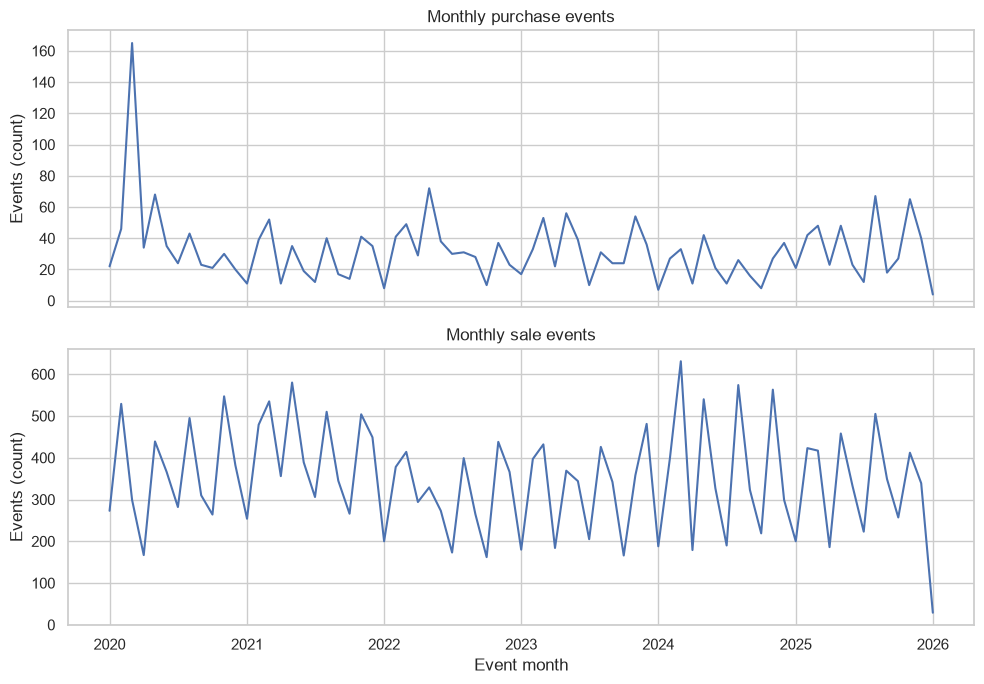

In [26]:
# 5c. Plot monthly event counts with separate scales for purchases and sales.
event_month = df_events["event_week"].dt.to_period("M")
monthly_events = (df_events.groupby([event_month, "trans_code"]).size().unstack(fill_value=0)
                  .reindex(pd.period_range(event_month.min(), event_month.max(), freq="M"), fill_value=0))
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, direction, label in zip(axes, ["P", "S"], ["Purchase", "Sale"]):
    sns.lineplot(x=monthly_events.index.to_timestamp(), y=monthly_events[direction].to_numpy(), ax=ax)
    ax.set(title=f"Monthly {label.lower()} events", ylabel="Events (count)", xlabel="Event month")
fig.tight_layout()
plt.show()

#### Interpretation: event timing

The highest purchase month is **March 2020 with 165 events**, compared with a median of **29** across observed purchase months. March 2020 clustering is consistent with purchases around the market downturn, but the count alone does not establish why insiders traded. Time clustering means observations should not be interpreted as independent repetitions of identical market conditions.

### Plot 2: How large are purchase events?

Dollar values span many orders of magnitude. Plotting **log_value**, the natural logarithm of total purchase dollars, lets small and large events appear together and motivates the planned regression's log transformation. Dollar tick labels translate the log axis back into familiar amounts; all positive values are retained.

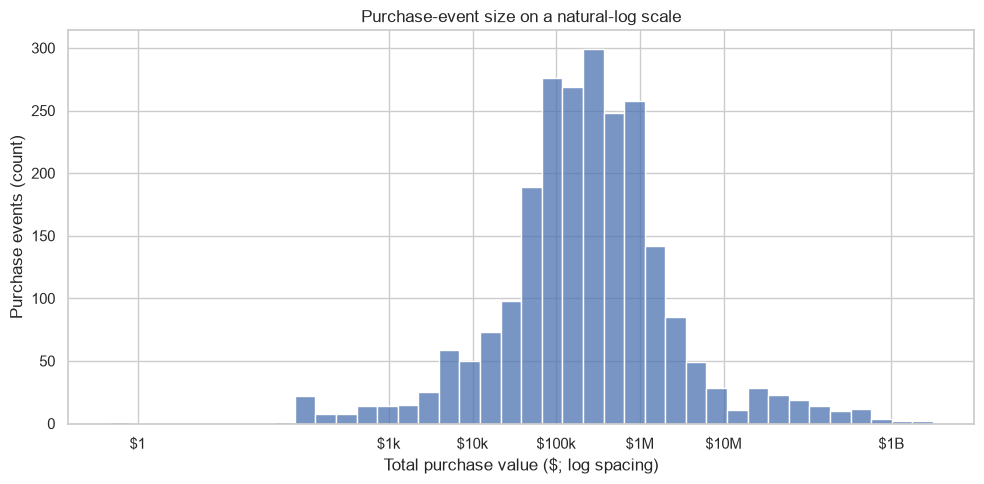

In [27]:
# 5d. Plot log purchase values with dollar labels on the logarithmic coordinates.
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=purchase_events, x="log_value", bins=40, ax=ax)
dollar_ticks = np.array([1, 1_000, 10_000, 100_000, 1_000_000, 10_000_000, 1_000_000_000])
ax.set_xticks(np.log(dollar_ticks), ["$1", "$1k", "$10k", "$100k", "$1M", "$10M", "$1B"])
ax.set(title="Purchase-event size on a natural-log scale", xlabel="Total purchase value ($; log spacing)", ylabel="Purchase events (count)")
fig.tight_layout()
plt.show()

#### Interpretation: purchase size

The median is **$241,795**, while the mean is **$10,834,728**, showing that large events pull up the average. Values range from **$0.46 to $3,121,679,536**. The log transformation compresses this range without deleting extremes. Very small and very large recorded events deserve review before Phase 3; this EDA does not claim their values measure information quality.

### Plot 3: Which roles appear in purchase events?

Role counts check whether the proposed role comparison has enough observations. Each event is assigned the most senior role under Step 2's ranking, so a bar counts events, not individual insiders. This chart uses **counts only**, with no post-event returns.

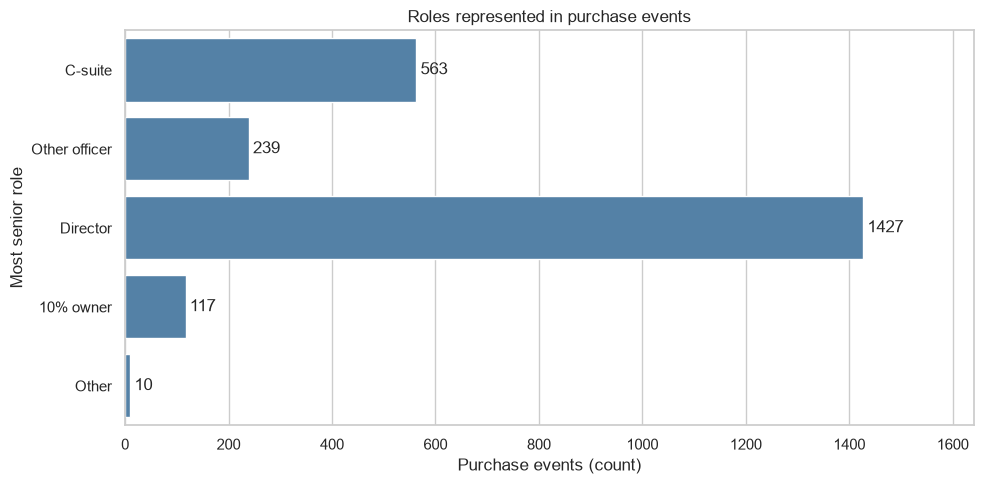

In [28]:
# 5e. Count purchase events by their most senior recorded insider role.
fig, ax = plt.subplots(figsize=(10, 5))
role_order = ["C-suite", "Other officer", "Director", "10% owner", "Other"]
sns.countplot(data=purchase_events, y="role", order=role_order, color="steelblue", ax=ax)
for container in ax.containers:
    ax.bar_label(container, padding=3)
ax.set(title="Roles represented in purchase events", xlabel="Purchase events (count)", ylabel="Most senior role")
ax.set_xlim(0, purchase_events["role"].value_counts().max() * 1.15)
fig.tight_layout()
plt.show()

#### Interpretation: role coverage

Directors account for **1,427 events (60.6%)**, followed by **563 C-suite**, **239 other-officer**, **117 10%-owner**, and **10 other events**. C-suite events can be contrasted with the remaining **1,793 events** in the planned model, subject to return availability. The small Other category does not support a detailed standalone comparison. Counts alone say nothing about which role predicts higher returns.

### Plot 4: How long after a trade is it filed?

Filing lag affects when an investor could learn about a trade. The existing `filing_lag_days` measures **calendar days**, so a line at 2 on that axis would not correctly mean two business days. We show calendar days on the left and a derived **weekday count** on the right, with the two-business-day reference on the weekday axis. The weekday count excludes weekends but not public holidays; this is a timing diagnostic, not a legal-compliance classification. Values above 30 are placed in the last bin, labeled 30+, rather than silently omitted.

Calendar lag percentiles: {0.5: 2.0, 0.9: 4.0, 0.99: 6.0}
Trades beyond 30 calendar days: 710


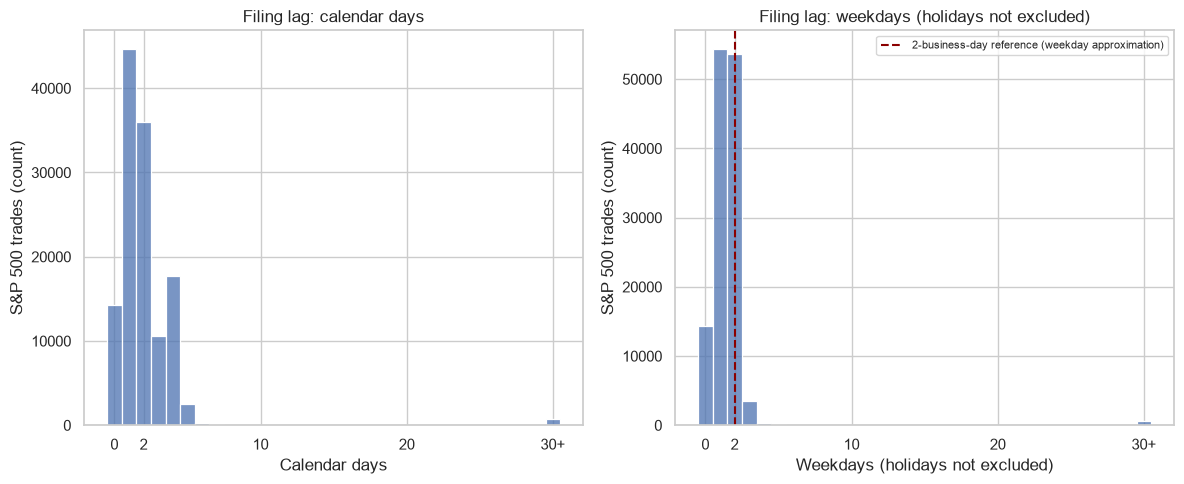

In [29]:
# 5f. Distinguish calendar-day filing lags from weekday lags and retain the long tail in a 30+ bin.
weekday_lag = np.busday_count(df_sp_trades["trans_date"].to_numpy(dtype="datetime64[D]"),
                              df_sp_trades["filing_date"].to_numpy(dtype="datetime64[D]"))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, values, label in [(axes[0], df_sp_trades["filing_lag_days"], "Calendar days"),
                           (axes[1], weekday_lag, "Weekdays (holidays not excluded)")]:
    sns.histplot(x=np.minimum(values, 30), bins=np.arange(-.5, 31, 1), ax=ax)
    ax.set(title=f"Filing lag: {label.lower()}", xlabel=label, ylabel="S&P 500 trades (count)")
    ax.set_xticks([0, 2, 10, 20, 30], ["0", "2", "10", "20", "30+"])
axes[1].axvline(2, color="darkred", linestyle="--", label="2-business-day reference (weekday approximation)")
axes[1].legend(fontsize=8)
print("Calendar lag percentiles:", df_sp_trades["filing_lag_days"].quantile([.5, .9, .99]).to_dict())
print("Trades beyond 30 calendar days:", df_sp_trades["filing_lag_days"].gt(30).sum())
fig.tight_layout()
plt.show()

#### Interpretation: disclosure timing

For the **S&P 500 trade sample**, median lag is **2 calendar days**, the 90th percentile is **4**, and the 99th percentile is **6**. There are **710 trades (0.56%)** beyond 30 days. This differs from the all-company SEC sample in the handoff, which has a longer tail. Timing variation supports anchoring events to disclosure rather than transaction dates. The weekday approximation cannot identify deadline violations, and the event-date rule itself still requires holiday-aware review before stronger timing claims.

### Plot 5: Price movement around the lead-up to an event

The `car_pre4` diagnostic sums abnormal returns over the four weeks **ending with the event week**. It checks whether purchases and sales occur around different recent price movements. Because the event week is included, this is not a strictly pre-disclosure measure: it can include a reaction after the filing. The boxplots show the median, middle half, and tails with all outlier points retained. This is not a comparison of the preregistered post-event outcomes.

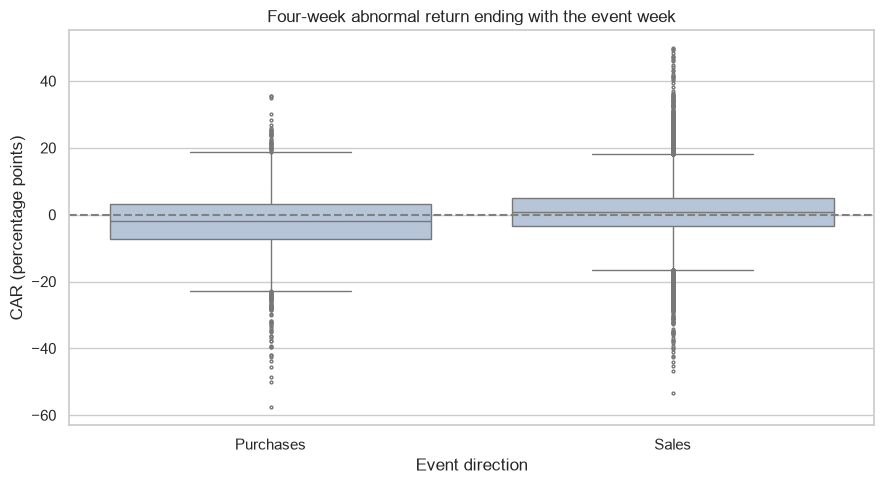

In [30]:
# 5g. Compare the four-week diagnostic ending with the event week across purchase and sale events.
pre_plot = df_events[["trans_code", "car_pre4"]].dropna().copy()
pre_plot["Direction"] = pre_plot["trans_code"].map({"P": "Purchases", "S": "Sales"})
pre_plot["CAR (percentage points)"] = pre_plot["car_pre4"] * 100
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=pre_plot, x="Direction", y="CAR (percentage points)", order=["Purchases", "Sales"],
            color="lightsteelblue", fliersize=2, ax=ax)
ax.axhline(0, color="gray", linestyle="--")
ax.set(title="Four-week abnormal return ending with the event week", xlabel="Event direction")
fig.tight_layout()
plt.show()

#### Interpretation: recent price movement

The median diagnostic is **-1.80 percentage points for purchases** and **0.81 for sales**. This is consistent with buying around recent declines and selling around recent gains. It does not show that insiders anticipated subsequent performance or establish a causal explanation. The inclusion of the event week limits a strictly pre-disclosure interpretation.

### Plot 6: Are proposed predictors closely related?

**Collinearity** means predictors carry overlapping information, which can make regression coefficients difficult to distinguish. Pearson correlation measures linear association; Spearman correlation compares ranks and is less sensitive to extreme magnitudes. These matrices use only predictors from purchase events with complete values for all five variables. **No CAR outcome is included.** Beta and filing lag provide context alongside the proposed model's C-suite flag, log value, and insider count.

Complete purchase events: 2,227; excluded for missing predictors: 129


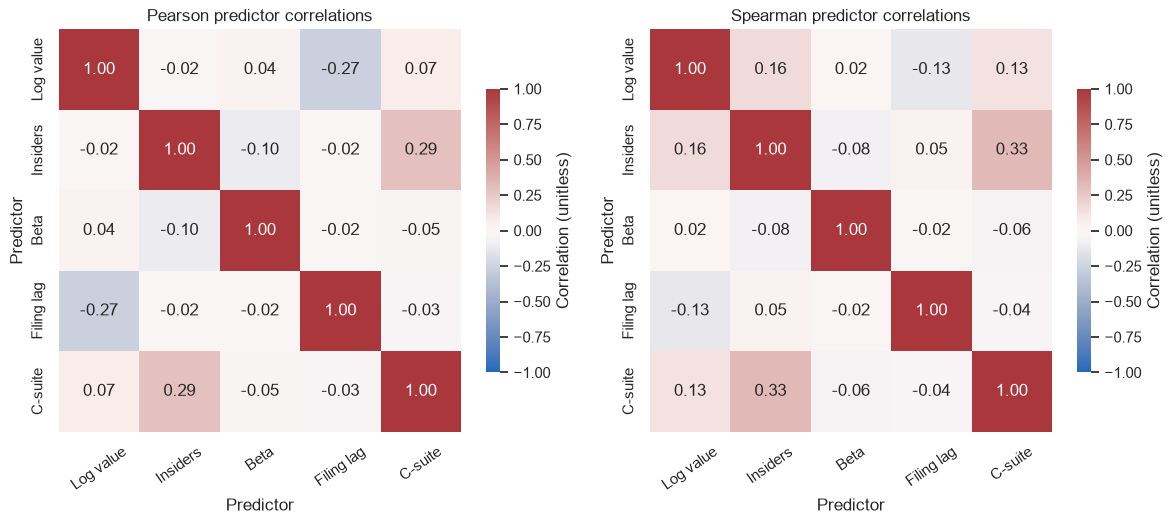

In [31]:
# 5h. Inspect Pearson and Spearman correlations among predictors only on one complete-case sample.
predictor_cols = ["log_value", "n_insiders", "beta", "mean_filing_lag", "any_c_suite"]
predictors = purchase_events[predictor_cols].dropna()
predictor_labels = ["Log value", "Insiders", "Beta", "Filing lag", "C-suite"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    correlation = predictors.corr(method=method)
    sns.heatmap(correlation, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag", square=True,
                xticklabels=predictor_labels, yticklabels=predictor_labels,
                cbar_kws={"label": "Correlation (unitless)", "shrink": .7}, ax=ax)
    ax.set(title=f"{method.title()} predictor correlations", xlabel="Predictor", ylabel="Predictor")
    ax.tick_params(axis="x", rotation=35)
print(f"Complete purchase events: {len(predictors):,}; excluded for missing predictors: {len(purchase_events) - len(predictors):,}")
fig.tight_layout()
plt.show()

#### Interpretation: predictor relationships

The matrices use **2,227 purchase events**, excluding **129** with incomplete predictors. The largest absolute off-diagonal correlation is **0.29 for Pearson** and **0.33 for Spearman**. C-suite participation and insider count have Pearson correlation **0.29**. These pairwise checks do not show near-duplicate predictors, but they cannot rule out multivariable collinearity; VIF and model diagnostics remain part of the later proposed analysis.

### What we learned from the EDA

- **Purchases are relatively rare:** 2,356 of 27,820 events (8.47%). We retain purchases as the main research focus and sales as the proposed comparison group.
- **Buying clusters in time:** March 2020 contains 165 purchase events, the largest monthly count. Market conditions and repeated companies limit independent-event interpretations.
- **Purchase size is highly uneven:** the median is $241,795 and the IQR is $907,546. This supports the planned log-value predictor; 563 C-suite events support keeping the broad role question.
- **Coverage is adequate but selected:** 2,227 purchase events have CARs at every horizon. There is no additional 26-week attrition in this saved dataset. Missing-price and estimation-window exclusions still constrain conclusions.
- **Disclosure and plan coverage need explicit definitions:** median S&P trade filing lag is 2 calendar days. Only 50 of 897 observed 2023+ purchase-event flags indicate a plan; the plan question is restricted to the later period and remains exploratory.
- **Diagnostics inform later modeling:** 19.27% of purchase events share a week with sales, and the purchase four-week diagnostic median is -1.80 percentage points. These motivate a mixed-week sensitivity check and careful discussion of recent price movements, without running the preregistered models.

**Changes to the research questions and data description:** The main question is retained, with purchases emphasized, a 2023-2025 restriction on the plan extension, and explicit 1-, 4-, 13-, and 26-week horizons. The description must identify rows as company-week-direction events, distinguish filing dates from event dates extending into January 2026, state the exact missing-return denominators, and avoid claiming late-2025 events necessarily lack 26-week outcomes. The written datasheet and preregistrations remain for Steps 6-7.

**Boundary of this EDA:** No research regression, significance test, or post-event return comparison by role, C-suite flag, or purchase size has been run. Separate outcome distributions have been examined as requested by the handoff; the later preregistrations should state that fact.

# __DATA DESCRIPTION__

### Motivation and intended use

This dataset was assembled for the Cornell INFO 2950 group project by Vansh Kakra, Dev Shukla, and Wilson Wang. Its purpose is to examine whether public insider disclosures contain information associated with subsequent stock returns beyond market movements. This relates to **market efficiency**, the extent to which prices already reflect available information. It is intended for educational, observational analysis, not individual surveillance, investment recommendations, or detecting illegal trading. No external sponsor is identified in the project materials.

The organization follows the motivation, composition, collection, preprocessing, and uses questions in [Gebru et al. (2018), *Datasheets for Datasets*](https://arxiv.org/abs/1803.09010).

### Composition: observations, coverage, and missingness

The analysis file, `data/processed/insider_events.csv`, contains **27,820 rows and 25 columns**. One observation is a unique **(issuer_cik, event_week, trans_code)** combination: one company, Friday-labeled week, and direction. A company with both buying and selling has two rows that week. The 593 companies are not 593 simultaneous index constituents; membership changes across the six-year filing period.

There are **2,356 purchase events in 459 companies** and **25,464 sale events in 582 companies**, derived from **6,358 purchase and 121,010 sale trade records**. Filing dates cover January 2, 2020 through December 31, 2025, while event weeks cover January 3, 2020 through January 2, 2026. The entry rule shifts some late-2025 filings into 2026. Selection is based on filings during the study period, not exclusively transaction dates during that period.

**Missing data:** 1,665 events lack a linked price ticker. Another 55 have a price ticker but no estimated beta, for **1,720 events without returns** in total. This leaves **26,100 events**, including 2,227 purchases and 23,873 sales, with all four CAR horizons. The 129 purchase events without returns comprise 114 without a price ticker and 15 additional events without beta. No extra 26-week attrition occurs in this saved snapshot. The plan flag is missing for **17,060 events**; missing is not coded as zero. Return exclusions are applied only when a particular analysis requires those values.

The interim files remain at a different unit: `sec_ps_trades.csv.gz` contains 692,025 cleaned SEC P/S trade rows across companies; `sp500_trades.csv.gz` contains the 127,368 matched S&P 500 trade rows. The membership and ticker-CIK files document matching. No train/test split is stored in the event file, and there are no hand-labeled outcomes: CARs are computed quantities.

### Data dictionary: all 25 event-table columns

CSV has no enforced schema. Read CIKs as strings to retain leading zeros and parse date columns explicitly. Returns are stored as decimals; multiply by 100 to express percentage points. The following types describe intended values, including missing numeric values where stated.

| Column | Type | Meaning and units |
|---|---|---|
| `issuer_cik` | String | Ten-digit SEC company identifier, including leading zeros. |
| `issuer_name` | String | First retained company name within the event; names may change over time. |
| `sp_ticker` | String | First retained historical index ticker for the event. |
| `price_ticker` | String, nullable | Linked ticker used for prices, selected by latest membership end among available histories. |
| `trans_code` | Category | P for purchase or S for sale, as reported in Form 4. |
| `event_week` | Date | Friday on or after filing date plus one weekday; event aggregation and entry label. |
| `first_filing` | Date | Earliest filing date among trades in this event. |
| `n_trades` | Integer | Number of retained trade rows in the event, not number of filings. |
| `n_insiders` | Integer | Number of distinct retained owner CIKs; joint filings can limit interpretation. |
| `total_value` | Float | Sum of reported shares times price per share, in nominal dollars. |
| `log_value` | Float | Natural logarithm of total dollar value, dimensionless. |
| `role` | Category | Most senior assigned role under the project's ranking. |
| `role_rank` | Integer | 1 C-suite, 2 Other officer, 3 Director, 4 10% owner, 5 Other. |
| `any_c_suite` | Binary integer | 1 if any retained trade has assigned C-suite rank, otherwise 0. |
| `any_plan_10b5_1` | Nullable binary | Maximum observed filing plan flag within the event; missing if all flags are missing. A zero can coexist with missing component flags. |
| `mixed_week` | Binary integer | 1 if the same company has both P and S events that week. |
| `mean_filing_lag` | Float | Mean filing date minus transaction date over event trades, in calendar days. |
| `alpha` | Nullable float | Market-model intercept, in weekly decimal-return units. |
| `beta` | Nullable float | Market-model slope against SPY, unitless. |
| `estimation_weeks` | Integer | Number of available return rows considered, up to 52; 0 when no series exists, with at least 40 required for a fit. |
| `car_pre4` | Nullable float | Sum of four abnormal weekly returns ending with the event week; decimal units, not strictly pre-disclosure. |
| `car_1w` | Nullable float | Sum of abnormal returns over the first week after the event week, decimal units. |
| `car_4w` | Nullable float | Sum over the first 4 weeks after the event week, decimal units. |
| `car_13w` | Nullable float | Sum over the first 13 weeks after the event week, decimal units. |
| `car_26w` | Nullable float | Sum over the first 26 weeks after the event week, decimal units. |

### Collection: sources, people, and observation mechanisms

The **SEC** is the primary source of legally mandated disclosures. Its records document reported transactions rather than verified motives or illegal conduct. **Historical membership** comes from a community-maintained resource that adds coverage of departed firms. **Yahoo Finance** supplies adjusted price histories, accessed through the third-party yfinance package. Each source supplies information the others lack: transactions, historical eligibility, and market outcomes, respectively.

Section 16 reporting obligations cover officers, directors, and beneficial owners above the relevant 10% threshold, not every employee or investor. Form 4 changes in ownership generally have a two-business-day reporting deadline. This creates a selected, self-reported sample with varying disclosure delays. See the [SEC investor bulletin](https://www.sec.gov/files/forms-3-4-5.pdf). The S&P 500 restriction further selects large companies. Vendor coverage, ticker changes, filing corrections, and title wording influence which observations survive matching.

The plan checkbox became required for applicable reports filed on or after **April 1, 2023**, according to the [SEC's 10b5-1 disclosure announcement](https://www.sec.gov/newsroom/modernizing-rule-10b5-1-insider-trading-plans). Earlier missingness cannot be interpreted as absence of a plan. Roles are derived from self-reported relationship fields and titles, not independently verified employment histories.

**People and awareness:** Filers provide identifying information for a public regulatory disclosure process. Public filing does not establish that they consented to this particular research use. We did not contact insiders or collect research consent, and cannot verify each person's understanding of downstream reuse. Raw files identify individuals and may include addresses; the final event table uses company identifiers and aggregated roles rather than insider names. Owner identifiers in interim data can still be linked to individuals. We avoid individual rankings or allegations.

### Preprocessing and reproducibility

Pandas loads and joins the tables, NumPy supports numerical calculations, and seaborn/Matplotlib produce EDA. DuckDB is available in the notebook environment; the implemented cleaning shown here is primarily pandas rather than a separate undocumented SQL pipeline. yfinance was used only for collection.

The appendix provides executable details: normalize membership intervals; keep Form 4/4-A P/S records; parse dates and numbers; require positive shares and prices and filing lags from 0 to 365 days; resolve superseded amendments; attach ranked roles; normalize ticker symbols; link index tickers to company CIKs with the 10% filing-share rule; match membership at the filing date; and remove cross-CIK duplicate trades. Prices are checked for duplicates and nonpositive closes, resampled to Friday-labeled weeks, and linked to one ticker per company.

Step 4 aggregates trades to events, takes log dollar value, estimates alpha and beta from up to 52 available weekly returns strictly before each event (minimum 40), and subtracts the market-model prediction from observed weekly returns. CAR is a sum of these differences, not a compounded trading-strategy return. Blank returns remain blank. The 25-column event CSV, intermediate files, source quarter labels, and notebook outputs support auditing; raw files are preserved.

### Uses, access, and source credit

Suitable uses include descriptive summaries and the limited course-method association models specified below. Unsuitable uses include inferring illegal trading, identifying individual wrongdoing, or presenting a guaranteed profitable strategy. The data do not contain experimental assignments or controls sufficient for causal claims. They are a fixed course-project snapshot, with no promised update schedule or independent audit of all source records.

Reviewers can obtain the [saved raw files](https://github.com/Vansh-Kakra/DSproject/tree/phase2-part1-sec-cleaning/insider-trading-phase2/data/raw), [intermediate files](https://github.com/Vansh-Kakra/DSproject/tree/phase2-part1-sec-cleaning/insider-trading-phase2/data/interim), and [processed files](https://github.com/Vansh-Kakra/DSproject/tree/phase2-part1-sec-cleaning/insider-trading-phase2/data/processed) from the project branch. Original sources are the [SEC quarterly datasets](https://www.sec.gov/data-research/sec-markets-data/insider-transactions-data-sets), [fja05680/sp500](https://github.com/fja05680/sp500), and [Yahoo Finance](https://finance.yahoo.com/) through [yfinance](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html). We credit the regulator, community maintainers, price provider, and software contributors; inclusion in this educational repository does not imply ownership of their data or unrestricted redistribution rights.

# __DATA LIMITATIONS__

### What limits the conclusions?

1. **Missing prices and selection bias.** Yahoo did not return 75 requested symbols. After ticker matching, 53 of 593 companies lack usable prices, affecting 4,511 retained trade records, including 271 purchases. At the event level, 1,665 events lack a price ticker and 55 more lack beta. Acquired, delisted, and failed companies are disproportionately difficult to retrieve, although missingness is not itself proof of failure. **Effect on conclusions:** observed returns may overrepresent surviving firms; the direction of bias is not known, and results cannot be generalized to all originally eligible events.

2. **Large-company scope and imperfect membership matching.** The sample covers S&P 500 members at filing dates, not the whole market. [Lakonishok and Lee (2001)](https://www.nber.org/papers/w6656) report stronger predictability in smaller firms, so a large-company sample may have weaker signals. Community membership dates, the 10% ticker-CIK matching threshold, renamed tickers, and share classes can introduce selection or linkage errors. **Effect on conclusions:** findings concern this matched large-company sample, and should not be extrapolated to small firms or treated as exact historical index reconstruction without additional checks.

3. **Weekly granularity and assumed entry timing.** Filing date plus `BDay(1)` counts weekdays, not exchange or SEC holidays, and does not use filing acceptance timestamps. Friday labels may represent Thursday prices on market holidays. The next-Friday rule can delay entry after a disclosure. **Effect on conclusions:** measured returns depend on this timing convention, especially at one week; a guarantee that every entry price follows actual public availability requires a holiday-aware and timestamp-aware audit. `car_pre4` includes the event week and may include post-disclosure reactions.

4. **Overlapping events and shared market conditions.** Repeated company events can reuse the same subsequent weekly returns. In addition, 454 purchase events (19.27%) share a week with sales. March 2020 has 165 purchase events. **Effect on conclusions:** rows are not independent, and raw event counts overstate independent information. Removing mixed weeks addresses conflicting signals, but does not remove all overlapping return windows or common shocks.

5. **Confounding company news.** Earnings announcements, buybacks, mergers, and changing fundamentals can influence both insider activity and stock returns. **Effect on conclusions:** even a positive association cannot establish that the disclosure caused the return or that an insider had private information.

6. **Market-model assumptions and changing risk.** A single SPY factor cannot capture industry or size effects. Historical alpha and beta can change, particularly around volatile periods such as 2020. The implementation uses up to 52 available return rows, which need not represent 52 consecutive calendar weeks if a history has gaps; the forward-window endpoint check also permits a one-week buffer. **Effect on conclusions:** some measured abnormal return can be model error or irregular price coverage. A near-zero or positive CAR is conditional on this benchmark, not an objective measure of mispricing.

7. **Sales and transaction-code interpretation.** Insiders can sell for liquidity, taxes, or diversification rather than pessimism. SEC P/S codes can include private transactions as well as exchange trades, so our operational P/S filter is broader than a verified exchange-only sample ([SEC Form 4 instructions](https://www.sec.gov/files/form4.pdf)). **Effect on conclusions:** sales are an imperfect comparison group, and the project's open-market wording should be interpreted as the P/S operational definition until individual transaction details are reviewed.

8. **Plan flags have limited coverage.** There are 17,060 missing event plan flags. Among 1,102 purchase events first filed in 2023 or later, 897 have observed flags, 205 have missing flags, and 50 have a recorded positive flag; the requirement began April 1, 2023. The event maximum can be zero even when some component flags are missing. **Effect on conclusions:** missing or zero flags are not comprehensive proof of discretionary trading, and a plan comparison must be restricted to the later period with explicit observed-flag denominators. The flag does not certify legal compliance.

9. **Role and owner measurement.** Titles are self-reported. The C-suite rule recognizes CEO, CFO, COO, and non-Vice-President President titles among officers, which can miss other senior titles or assign ambiguous titles incorrectly. Filing-level roles select the highest-ranked reporting owner, while event insider counts use retained owner CIKs. **Effect on conclusions:** role coefficients would describe our classification rather than a perfectly measured executive hierarchy, and joint filers can distort the link between a role and a particular trade.

10. **Amendments, duplicates, and recorded value extremes.** Amendments and cross-CIK duplicate rules are reproducible heuristics, not a manual audit of each filing. Purchase-event values range from $0.46 to about $3.12 billion. Large beneficial-owner filings may represent different behavior from ordinary executive purchases. **Effect on conclusions:** residual reporting errors and unusual transactions can influence summaries and regression fits; log value reduces scale differences but does not establish validity. Any later exclusions must be documented rather than chosen to improve a result.

11. **Vendor prices and strategy realism.** Yahoo adjusted prices are a vendor product, not CRSP; adjustments, stale observations, share classes, and historical revisions may differ across providers. The latest saved date can include an incomplete trading day. CAR adds abnormal weekly returns and omits transaction costs, taxes, execution constraints, and portfolio weighting. **Effect on conclusions:** results describe benchmark-relative event outcomes, not the net return an outside investor could necessarily earn. The current 26-week outcomes end well before the last saved price date, but broader reuse needs fresh coverage checks.

### Potential harms and impact on people

Publicly reported trading is not evidence of illegal insider trading. Attaching allegations to named individuals could damage reputations and misrepresent routine financial decisions. We report company-event patterns and avoid ranking or accusing individuals. Public source records can still identify people; aggregating and linking them can make personal financial behavior easier to scrutinize even when no new private data are collected.

A positive result could encourage retail investors to copy trades while bearing timing, concentration, and loss risks that the study does not measure. A null result could also be overstated as proof that disclosures never matter. We will report limitations alongside results, distinguish association from causation, and avoid presenting the project as investment advice. Missing-company coverage and classification errors can affect which people and firms appear successful, making unqualified rankings especially misleading.

# __PREREGISTRATION STATEMENT 1__

### Purchase disclosures and subsequent abnormal returns

A **preregistration** records the question, sample, and analysis choices before running the specified analysis, reducing freedom to choose a favorable method afterward.

**Status and prior exposure:** This plan is recorded after Steps 1-5 and before fitting the research models. Step 5 has already displayed separate purchase and sale CAR means, medians, and distributions, so this is not an outcome-blind preregistration. No purchase-versus-sale research regression, formal significance test, or post-event CAR comparison by role, C-suite status, or purchase size has been run. The existing EDA is disclosed rather than described as unseen data. Any later deviation will be labeled and justified in the final report.

**Hypothesis:** The average **13-week CAR after purchase events is positive and exceeds the average after sale events**. The primary horizon is 13 weeks; 1, 4, and 26 weeks provide secondary descriptive context.

**Motivation:** [Lakonishok and Lee (2001), *Are Insider Trades Informative?*](https://www.nber.org/papers/w6656) find purchases more informative than sales, with important firm-size differences. [Jeng, Metrick, and Zeckhauser (2003), *Estimating the Returns to Insider Trading: A Performance-Evaluation Perspective*](https://rzeckhauser.scholars.harvard.edu/publications/estimating-returns-insider-trading-performance-evaluation-perspective) report abnormal performance for purchase portfolios but not comparable evidence for sale portfolios. These findings motivate a directional hypothesis; their samples, weighting, and transaction timing differ from our public-disclosure event design and do not guarantee the result here.

### Definitions, eligible sample, and exclusions

The unit is one **company-week-direction event**, equally weighted regardless of its dollar value. Eligible filings are retained Form 4/4-A P/S records from 2020-2025 at companies matched to S&P 500 membership on the filing date. P/S is the operational purchase/sale definition and can include private transactions. Entry uses the **first Friday close on or after filing date plus one business day**, as implemented by a weekday offset; holiday and filing-time limitations are documented above.

The market model estimates alpha and beta using up to **52 available weekly returns strictly before the event week**, requiring at least **40**. Weekly abnormal return is actual stock return minus the model prediction (alpha plus beta times SPY return), written as `actual - (alpha + beta * market_return)`. `car_13w` sums the next 13 weekly abnormal returns, excluding the event week. It is stored in decimal units.

Use events with observed `car_13w` and a P/S direction. The current eligible sample is **26,100 events: 2,227 purchases and 23,873 sales**. Exclude missing price histories, insufficient estimation history, and missing outcomes; do not impute zero returns. Keep `mixed_week = 1` events in the primary analysis. Do not trim or winsorize valid outcomes based on their value. Report the retained counts and exclusions.

### Proposed course-method analysis and interpretation

Fit ordinary least squares with an intercept using `sklearn.linear_model.LinearRegression`:

`car_13w = intercept + beta_purchase * is_purchase + error`

`is_purchase` is 1 for P and 0 for S, so **sales are the reference group**. The intercept estimates average sale CAR; `beta_purchase` estimates the purchase-minus-sale difference. The implied purchase mean is `intercept + beta_purchase`. The hypothesis predicts **both `beta_purchase > 0` and `intercept + beta_purchase > 0`**. Assess those signs and magnitudes explicitly; a positive difference alone does not establish a positive purchase mean.

Report both group means, the coefficient and implied purchase mean in percentage points, and purchase-only mean CARs at 1, 4, 13, and 26 weeks with their available counts. A decimal coefficient of 0.01 represents a one-percentage-point difference. These are directional, descriptive assessments using course tools; **no t-tests, p-values, significance threshold, or claims of statistical significance are planned**. In particular, repeated events and overlapping windows do not justify treating every row as independent evidence.

**Sensitivity analysis:** Repeat the same 13-week model after excluding `mixed_week = 1` events, reporting the new counts and coefficient alongside the primary result. This sensitivity check does not fix other window overlap. Report positive, zero, negative, and inconsistent results, regardless of whether they support the hypothesis. A null or opposite sign will not trigger a switch of the primary horizon. Further specifications will be labeled exploratory.

# __PREREGISTRATION STATEMENT 2__

### Insider role and purchase size

**Status and prior exposure:** This plan is recorded after Steps 1-5 and before fitting the research models. Step 5 has already displayed separate purchase and sale CAR means, medians, and distributions, so this is not an outcome-blind preregistration. No purchase-versus-sale research regression, formal significance test, or post-event CAR comparison by role, C-suite status, or purchase size has been run. The existing EDA is disclosed rather than described as unseen data. Any later deviation will be labeled and justified in the final report.

**Hypothesis:** Among purchase events, **C-suite participation and larger dollar purchase values are associated with higher 13-week CARs**, controlling for the number of recorded insiders.

**Motivation:** Executives may have broad access to company information, and committing more dollars may indicate stronger conviction, although wealth and liquidity can also explain purchase size. [Seyhun (1986), *Insiders' Profits, Costs of Trading, and Market Efficiency*](https://doi.org/10.1016/0304-405X(86)90060-7) motivates examining differences in information by insider position. [Cohen, Malloy, and Pomorski (2012), *Decoding Inside Information*](https://corpgov.law.harvard.edu/2012/02/03/decoding-inside-information/) distinguish routine trading from more informative trading. Their classification is not equivalent to our C-suite flag or 10b5-1 checkbox. The literature motivates heterogeneity, not certainty that our exact role proxy or larger nominal purchases will predict better outcomes. Jeng, Metrick, and Zeckhauser (2003) also find that top executives do not outperform other insiders in their setting, so the role hypothesis faces meaningful contrary evidence.

### Sample, measurements, and fixed model

Use **purchase events only** (`trans_code = P`) with observed `car_13w`, `any_c_suite`, `log_value`, and `n_insiders`, currently **2,227 events**. Apply Statement 1's filing scope, event unit, entry rule, market model, and return definition. Exclude missing required values without imputation and report exclusions. Keep valid extreme values and mixed weeks in the primary model. Each event receives equal weight.

`any_c_suite` equals 1 when an event includes a trade assigned C-suite rank: an officer title matching CEO, CFO, COO, their expanded names, or President excluding Vice President. Zero includes directors, other officers, 10% owners, and Other; it is **not a directors-only reference group**. `log_value` is the natural logarithm of total reported purchase dollars. `n_insiders` counts distinct retained owner CIKs. Joint-filing and title limitations apply.

Fit the following multivariable linear regression with an intercept using `LinearRegression`:

`car_13w = intercept + beta_c_suite * any_c_suite + beta_log_value * log_value + beta_insiders * n_insiders + error`

The directional predictions are **`beta_c_suite > 0` and `beta_log_value > 0`**. Report the two predictions separately; support for one does not imply support for both. The C-suite coefficient is an adjusted difference in decimal CAR at the same recorded log value and insider count. For a 1% larger purchase, the exact modeled difference is `beta_log_value * log(1.01)`, approximately `0.01 * beta_log_value` in decimal CAR, holding other predictors fixed. Multiply by 100 to express percentage points. These are associations, not causal effects. No interactions, extra controls, or outcome-driven variable selection are included in the primary specification.

### Diagnostics, prediction check, and reporting

1. **Collinearity:** Report predictor Pearson/Spearman correlations and variance inflation factors (VIF). Compute each VIF as `1 / (1 - R_squared)` from regressing one predictor on the others with an intercept. Large values indicate overlapping predictor information. Discuss the diagnostics without automatically dropping a prespecified variable to improve its coefficient.
2. **Prediction evaluation:** Make one random **70% training / 30% test split**, using `train_test_split(test_size=0.30, random_state=2950)`. Fit the fixed specification on the training subset only. Evaluate once on the held-out test subset with **RMSE**, the square root of mean squared prediction error, and compare with a baseline that always predicts the training outcome mean. Report RMSE in percentage points and both sample sizes. Examine a training residual-versus-fitted plot for systematic patterns and unequal spread; do not tune the model on test outcomes.
3. **Association estimates:** Fit the same fixed specification on all eligible purchase events for descriptive coefficients, explicitly distinguishing that full-sample fit from the model used for held-out RMSE. Report every coefficient, its units, and the sign of each prespecified directional prediction. No t-tests, p-values, or statistical-significance claims are planned.
4. **Dependence caveat and sensitivity:** A random event split can place the same company and overlapping outcome periods in both subsets. Test RMSE therefore measures this random-split task and is not an estimate of independent future-period performance. Repeat the fixed full-sample association model after excluding mixed weeks, and present it beside the primary model. A time-ordered or company-grouped validation scheme is a reviewer question for Phase 3, not an undisclosed replacement chosen after results.

**Later-period extension:** Leave `any_plan_10b5_1` out of the main model. A separately labeled exploratory Phase 3 analysis may consider 2023-2025 filings with observed flags, starting no earlier than April 1, 2023 and checking component-flag coverage. The small positive-flag purchase sample limits precision. We do not include the optional logistic model in this primary plan, to keep the analysis focused and feasible.

Report results whether supportive, contradictory, or inconclusive. Fixed coefficients and limited prediction error do not establish market-beating profits, private information, or wrongdoing. Any model changes after this commit will be documented as deviations or exploratory follow-up.

# __QUESTIONS FOR REVIEWERS__

### Decisions to resolve before Phase 3

These questions arise from the group's documented project choices and the executed EDA. They are proposed discussion questions, not a claim that an additional group meeting or vote has occurred.

1. **Entry timing:** Is our Friday entry after filing date plus one weekday adequate, especially at the one-week horizon, or should we use filing acceptance timestamps and an exchange-holiday calendar? Would daily returns materially improve the short-horizon question?
2. **Repeated events:** Should we keep only the first company event within each 26-week window, or retain all events and limit claims about independence? Such thinning removes shared windows within a company but not common market shocks. How should we weigh the loss of purchase events against less overlap?
3. **Market benchmark:** Is the 52-observation SPY market model sufficient for this large-company sample, or should Phase 3 include a course-compatible industry or size adjustment? Should we require strictly consecutive estimation weeks rather than the last available weekly rows?
4. **Missing-company coverage:** With 53 companies lacking usable prices (75 failed symbols before company matching), is documenting the selection bias enough for Phase 3, or should we seek another source for acquired and delisted firms before interpreting returns?
5. **Role definition:** Is grouping CEO, CFO, COO, and non-Vice-President President as C-suite appropriate? Should directors be an explicit separate dummy rather than part of the broad non-C-suite reference, given 1,427 director and 563 C-suite purchase events before return exclusions?
6. **Validation and prior exposure:** Is the required random 70/30 event split acceptable if accompanied by its overlap caveat, or should a time-ordered/company-grouped check be primary? Since EDA already showed separate outcome distributions, is our explicit disclosure of that exposure sufficient for the course preregistration requirement?
7. **Plan and transaction definitions:** For the small 2023+ positive-plan purchase sample, should we defer the extension until filing-level checkbox coverage is audited? Should P/S transactions be reviewed for private transactions before using the term open-market in the final interpretation?